In [ ]:
"""
SESI 1 - Analitik dan AI: studi kasus PT MAJU BERSAMA (dataset SINTETIS)

Mengikuti materi Andria Arisal:
  * ~120 pelanggan, 24 produk, ~24.000 baris invoice, 1 Jul 2024 - 30 Jun 2026
  * Kondisi: pendapatan NAIK, laba bersih TURUN, piutang (accounts receivable) NAIK
  * Alur: pemahaman bisnis -> persiapan data -> modeling (descriptive, diagnostic,
    predictive, prescriptive) -> evaluasi -> rekomendasi
  * Pemeriksaan kualitas data: missing, duplikasi, kejadian tak mungkin, kategori tidak
    konsisten, relasi tabel rusak, diskon ekstrem
  * Jebakan granularitas join, class imbalance (accuracy ~89% tetapi recall ~0), data leakage
  * Perbaikan: buang leakage, class_weight, fitur riwayat + kalender, temporal split,
    metrik recall/precision
  * Next steps: operating expenses, waktu bayar, segmen pelanggan, margin per produk

PENTING: datanya dibuat oleh kode ini agar cocok dengan cerita materi. Bukan data asli
PT Maju Bersama milik pemateri. Jalankan: python sesi1_pt_maju_bersama.py
"""
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(2024)
N_CUST, N_PROD, N_INV, T = 120, 24, 24_000, 24
BULAN = pd.period_range("2024-07", "2026-06", freq="M")


def judul(t):
    print("\n" + "=" * 72 + f"\n{t}\n" + "=" * 72)


# ============================================================ 1. DATA SINTETIS
cust = pd.DataFrame({
    "cust_id": np.arange(N_CUST),
    "segmen": rng.choice(["korporat", "UKM", "ritel"], N_CUST, p=[.2, .5, .3]),
    "credit_limit": rng.choice([50, 100, 200, 500], N_CUST) * 1_000_000,
})
base_risk = cust.segmen.map({"korporat": .03, "UKM": .10, "ritel": .07}).values
cust["risk"] = 0.65 * base_risk * rng.lognormal(0, .6, N_CUST)      # sifat pelanggan menetap

prod = pd.DataFrame({
    "prod_id": np.arange(N_PROD),
    "kategori": np.repeat(["A", "B", "C", "D"], N_PROD // 4),
    "unit_cost": rng.uniform(40_000, 400_000, N_PROD),
})
prod["list_price"] = prod.unit_cost * prod.kategori.map({"A": 1.45, "B": 1.40, "C": 1.35, "D": 1.40})

# volume invoice naik sepanjang 24 bulan
bln = rng.choice(T, N_INV, p=np.linspace(1, 1.6, T) / np.linspace(1, 1.6, T).sum())
tgl = pd.to_datetime(BULAN[bln].to_timestamp()) + pd.to_timedelta(rng.integers(0, 28, N_INV), unit="D")
inv = pd.DataFrame({
    "invoice_id": np.arange(N_INV),
    "cust_id": rng.integers(0, N_CUST, N_INV),
    "prod_id": rng.integers(0, N_PROD, N_INV),
    "invoice_date": tgl,
    "qty": rng.integers(1, 30, N_INV),
    "terms_days": rng.choice([14, 30, 45], N_INV),
})
inv = inv.merge(prod[["prod_id", "kategori"]], on="prod_id")
t_idx = inv.invoice_date.dt.to_period("M").map({p: i for i, p in enumerate(BULAN)}).values
# promo kategori C makin agresif -> margin tergerus
inv["discount"] = np.clip(rng.normal(.04, .02, N_INV) + np.where(inv.kategori == "C", .0045 * t_idx, 0), 0, None)
inv["due_date"] = inv.invoice_date + pd.to_timedelta(inv.terms_days, unit="D")

tmp = inv.merge(cust[["cust_id", "risk"]], on="cust_id").merge(prod[["prod_id", "unit_cost", "list_price"]], on="prod_id")
tmp = tmp.sort_values("invoice_id").reset_index(drop=True)
inv = inv.sort_values("invoice_id").reset_index(drop=True)
tm = tmp.invoice_date.dt.to_period("M").map({p: i for i, p in enumerate(BULAN)}).values
p_long = np.clip(tmp.risk.values * (0.7 + 1.2 * tm / (T - 1)), 0, .7)   # risiko telat naik seiring waktu
long_late = rng.random(N_INV) < p_long
inv["days_late"] = np.where(long_late, 31 + rng.gamma(3, 10, N_INV),
                            np.clip(rng.gamma(2, 3, N_INV) - 4, -5, 30)).round()
inv["payment_date"] = inv.due_date + pd.to_timedelta(inv.days_late, unit="D")
inv["unpaid_30d"] = (inv.days_late > 30).astype(int)               # TARGET prediksi
inv["revenue"] = tmp.qty * tmp.list_price * (1 - inv.discount)
inv["cogs"] = tmp.qty * tmp.unit_cost
inv["gross_profit"] = inv.revenue - inv.cogs

# biaya operasional bulanan: tumbuh lebih cepat daripada laba kotor
gp_bln = inv.groupby(inv.invoice_date.dt.to_period("M")).gross_profit.sum()
opex = pd.Series(gp_bln.iloc[0] * 0.70 * (1 + 0.035 * np.arange(T)), index=BULAN, name="opex")

# ---- kotori data (agar pemeriksaan kualitas bermakna) ----
raw = inv.merge(cust[["cust_id", "segmen", "credit_limit"]], on="cust_id")
raw.loc[rng.choice(len(raw), 150, replace=False), "segmen"] = "ukm "           # kategori tak konsisten
raw.loc[raw.segmen == "UKM", "segmen"] = rng.choice(["UKM", "ukm", "Ukm"], (raw.segmen == "UKM").sum(), p=[.97, .02, .01])
raw.loc[rng.choice(len(raw), 120, replace=False), "discount"] = np.nan          # missing
raw.loc[rng.choice(len(raw), 40, replace=False), "discount"] = rng.uniform(.6, .9, 40)  # diskon ekstrem
raw.loc[rng.choice(len(raw), 25, replace=False), "qty"] = 0                     # kejadian tak mungkin
raw.loc[rng.choice(len(raw), 20, replace=False), "cust_id"] = 999               # relasi rusak
raw = pd.concat([raw, raw.sample(60, random_state=1)])                          # duplikasi

# ============================================================ 2. KUALITAS DATA
judul("2. PEMERIKSAAN KUALITAS DATA (persiapan data)")
print(f"baris mentah: {len(raw):,}")
print("missing discount        :", int(raw.discount.isna().sum()))
print("invoice_id duplikat     :", int(raw.invoice_id.duplicated().sum()))
print("qty <= 0 (tak mungkin)  :", int((raw.qty <= 0).sum()))
print("cust_id tidak ada master:", int((~raw.cust_id.isin(cust.cust_id)).sum()))
print("kategori segmen         :", sorted(raw.segmen.dropna().unique()))
print("diskon > 50% (anomali)  :", int((raw.discount > .5).sum()), "-> DIVERIFIKASI MANUSIA, bukan dibuang otomatis")

df = raw.drop_duplicates("invoice_id").copy()
df = df[df.qty > 0]
df = df[df.cust_id.isin(cust.cust_id)]
df["segmen"] = df.segmen.str.strip().str.upper().replace({"UKM": "UKM", "KORPORAT": "korporat", "RITEL": "ritel"})
df["discount"] = df.discount.fillna(df.groupby("kategori").discount.transform("median"))
df["anomali_diskon"] = (df.discount > .5).astype(int)        # ditandai untuk ditinjau pakar domain
df = df.sort_values("invoice_id").reset_index(drop=True)
print(f"baris setelah pembersihan: {len(df):,}")

# ---- granularitas: join yang salah menggandakan baris ----
cust_bulan = pd.DataFrame({"cust_id": np.repeat(cust.cust_id, T), "bulan": np.tile(BULAN, N_CUST)})
salah = df.merge(cust_bulan, on="cust_id")               # level invoice x level pelanggan-bulan
print(f"\n[Granularitas] join benar (m:1): {len(df):,} baris | join salah ke tabel pelanggan-bulan: "
      f"{len(salah):,} baris (terduplikasi ~{len(salah) / len(df):.0f}x -> total pendapatan menjadi salah)")
df["bulan"] = df.invoice_date.dt.to_period("M")

# ============================================================ 3. DESCRIPTIVE
judul("3. DESCRIPTIVE - apa yang terjadi? (juta Rp)")
rev = df.groupby("bulan").revenue.sum()
gp = df.groupby("bulan").gross_profit.sum()
net = gp - opex
ar = pd.Series({b: df[(df.bulan <= b) & (df.payment_date > b.to_timestamp(how="end"))].revenue.sum()
                for b in BULAN})
ringkas = pd.DataFrame({"pendapatan": rev, "laba_bersih": net, "piutang_akhir_bulan": ar}) / 1e6
print(ringkas.iloc[[0, 1, 2, -3, -2, -1]].round(0).to_string())
q1, q2 = ringkas.iloc[:3].mean(), ringkas.iloc[-3:].mean()
print("\nperubahan rata-rata 3 bulan pertama -> 3 bulan terakhir:")
print(((q2 / q1 - 1) * 100).round(1).astype(str).add("%").to_string())

# ============================================================ 4. DIAGNOSTIC
judul("4. DIAGNOSTIC - mengapa? (operating expenses, margin produk, segmen pelanggan)")
awal, akhir = df.bulan <= BULAN[5], df.bulan >= BULAN[-6]
print("Opex vs laba kotor (3 bln awal -> 3 bln akhir, juta Rp):")
print(f"  laba kotor {gp.iloc[:3].mean() / 1e6:,.0f} -> {gp.iloc[-3:].mean() / 1e6:,.0f} | "
      f"opex {opex.iloc[:3].mean() / 1e6:,.0f} -> {opex.iloc[-3:].mean() / 1e6:,.0f}")
mg = pd.DataFrame({"margin_awal_%": df[awal].groupby("kategori").apply(lambda g: g.gross_profit.sum() / g.revenue.sum() * 100),
                   "margin_akhir_%": df[akhir].groupby("kategori").apply(lambda g: g.gross_profit.sum() / g.revenue.sum() * 100)})
print("\nMargin per kategori produk (6 bln awal vs 6 bln akhir):\n", mg.round(1).to_string())
tel = pd.DataFrame({"telat>30h_awal_%": df[awal].groupby("segmen").unpaid_30d.mean() * 100,
                    "telat>30h_akhir_%": df[akhir].groupby("segmen").unpaid_30d.mean() * 100})
print("\nInvoice belum dibayar 30 hari setelah jatuh tempo per segmen:\n", tel.round(1).to_string())

# ============================================================ 5. PREDICTIVE
judul("5. PREDICTIVE - invoice mana yang masih belum dibayar 30 hari setelah jatuh tempo?")
print(f"proporsi kelas positif: {df.unpaid_30d.mean():.1%}  (class imbalance)")


def riwayat_telat(d, prior):
    """Rasio telat historis pelanggan, hanya dari invoice yang hasilnya SUDAH diketahui
    saat invoice ini terbit (hasil diketahui pada jatuh tempo + 30 hari). Tanpa kebocoran."""
    out = pd.Series(index=d.index, dtype=float)
    for _, g in d.groupby("cust_id"):
        known = (g.due_date + pd.Timedelta(days=30)).values
        o = np.argsort(known)
        ks, cs = known[o], np.cumsum(g.unpaid_30d.values[o])
        n = np.searchsorted(ks, g.invoice_date.values, side="right")
        k = np.where(n > 0, cs[np.maximum(n - 1, 0)], 0)
        out.loc[g.index] = (k + prior * 5) / (n + 5)
    return out


df["riwayat_telat"] = riwayat_telat(df, prior=df.unpaid_30d.mean())
df["bulan_ke"] = df.invoice_date.dt.month                            # fitur kalender
df["akhir_tahun"] = df.invoice_date.dt.month.isin([11, 12]).astype(int)
df["promo"] = (df.discount > .08).astype(int)
seg = pd.get_dummies(df.segmen, prefix="seg").astype(float)
dasar = ["qty", "discount", "terms_days", "credit_limit", "revenue"]
X_dasar = pd.concat([df[dasar], seg], axis=1)
X_baik = pd.concat([X_dasar, df[["riwayat_telat", "bulan_ke", "akhir_tahun", "promo"]]], axis=1)
X_leak = X_dasar.assign(days_late=df.days_late)                      # BOCOR: info setelah pembayaran
y = df.unpaid_30d

cut = pd.Timestamp("2025-12-31")          # temporal split: latih masa lalu, uji masa depan
tr, te = (df.invoice_date <= cut).values, (df.invoice_date > cut).values
print(f"latih: {tr.sum():,} invoice (s.d. Des 2025) | uji: {te.sum():,} invoice (Jan-Jun 2026)\n")


def jalankan(nama, model, X):
    model.fit(X[tr], y[tr])
    p = model.predict(X[te])
    print(f"{nama:<50} accuracy={accuracy_score(y[te], p):.3f} recall={recall_score(y[te], p, zero_division=0):.3f} "
          f"precision={precision_score(y[te], p, zero_division=0):.3f} F1={f1_score(y[te], p, zero_division=0):.3f}")
    return model


rf = lambda **k: RandomForestClassifier(200, random_state=0, n_jobs=-1, **k)
jalankan("A. Random Forest, fitur dasar, tanpa penanganan", rf(), X_dasar)
jalankan("A2. Logistic Regression, fitur dasar", make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)), X_dasar)
jalankan("B. + fitur BOCOR days_late (tidak realistis)", rf(), X_leak)
jalankan("C. RF + class_weight, fitur dasar", rf(class_weight="balanced_subsample", min_samples_leaf=5), X_dasar)
model = jalankan("D. RF + class_weight + riwayat + kalender", rf(class_weight="balanced_subsample", min_samples_leaf=5), X_baik)

print("\nCatatan:")
print(" A  : accuracy tinggi tetapi recall ~0 -> model hampir selalu menebak 'akan dibayar'.")
print(" B  : hampir sempurna karena leakage -> fitur ini harus DIBUANG.")
print(" C/D: recall naik setelah imbalance ditangani dan fitur diperkaya (riwayat pelanggan, kalender, promo).")

# ============================================================ 6. PRESCRIPTIVE
judul("6. PRESCRIPTIVE - apa yang sebaiknya dilakukan?")
uji = df[te].copy()
uji["skor_risiko"] = model.predict_proba(X_baik[te])[:, 1]
per_cust = (uji.groupby(["cust_id", "segmen", "credit_limit"]).agg(skor=("skor_risiko", "mean"),
                                                                    nilai_invoice=("revenue", "sum"))
            .reset_index().sort_values("skor", ascending=False))
print("10 pelanggan berisiko tertinggi (kandidat penagihan terarah / pengetatan credit limit):")
print(per_cust.head(10).assign(nilai_invoice=lambda d: (d.nilai_invoice / 1e6).round(0)).round(2).to_string(index=False))

# simulasi skenario SEDERHANA (asumsi, bukan hasil pengukuran): penagihan dini ke 20% invoice berisiko tertinggi
asumsi = 0.30
k = int(len(uji) * .20)
tinggi = uji.nlargest(k, "skor_risiko")
selamat = (tinggi.unpaid_30d * tinggi.revenue).sum() * asumsi
total = (uji.unpaid_30d * uji.revenue).sum()
print(f"\nSkenario (ASUMSI penagihan dini mengurangi telat {asumsi:.0%} pada 20% invoice teratas):")
print(f"  piutang telat >30 hari: Rp{total / 1e6:,.0f} juta -> sekitar Rp{(total - selamat) / 1e6:,.0f} juta")
print("  (Materi menyebut simulasi Markov/multi-agent untuk skenario yang lebih lengkap.)")
print(f"  Diskon ekstrem yang perlu ditinjau manusia: {int(df.anomali_diskon.sum())} invoice.")


2. PEMERIKSAAN KUALITAS DATA (persiapan data)
baris mentah: 24,060
missing discount        : 120
invoice_id duplikat     : 60
qty <= 0 (tak mungkin)  : 25
cust_id tidak ada master: 20
kategori segmen         : ['UKM', 'Ukm', 'korporat', 'ritel', 'ukm', 'ukm ']
diskon > 50% (anomali)  : 40 -> DIVERIFIKASI MANUSIA, bukan dibuang otomatis
baris setelah pembersihan: 23,955

[Granularitas] join benar (m:1): 23,955 baris | join salah ke tabel pelanggan-bulan: 574,920 baris (terduplikasi ~24x -> total pendapatan menjadi salah)

3. DESCRIPTIVE - apa yang terjadi? (juta Rp)
         pendapatan  laba_bersih  piutang_akhir_bulan
2024-07      2912.0        223.0               2361.0
2024-08      2889.0        195.0               3158.0
2024-09      3284.0        279.0               3574.0
2026-04      4658.0        182.0               5734.0
2026-05      4617.0        173.0               5485.0
2026-06      4543.0        129.0               5576.0

perubahan rata-rata 3 bulan pertama -> 3 bulan t

/tmp/ipykernel_8477/3114260915.py:142: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  mg = pd.DataFrame({"margin_awal_%": df[awal].groupby("kategori").apply(lambda g: g.gross_profit.sum() / g.revenue.sum() * 100),
/tmp/ipykernel_8477/3114260915.py:143: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "margin_akhir_%": df[akhir].groupby("kategori").apply(lambda g: g.gross_profit.sum() / g.revenue.sum() * 100)})


latih: 16,907 invoice (s.d. Des 2025) | uji: 7,048 invoice (Jan-Jun 2026)

A. Random Forest, fitur dasar, tanpa penanganan    accuracy=0.883 recall=0.008 precision=0.146 F1=0.014
A2. Logistic Regression, fitur dasar               accuracy=0.887 recall=0.000 precision=0.000 F1=0.000
B. + fitur BOCOR days_late (tidak realistis)       accuracy=1.000 recall=1.000 precision=1.000 F1=1.000
C. RF + class_weight, fitur dasar                  accuracy=0.867 recall=0.042 precision=0.160 F1=0.066
D. RF + class_weight + riwayat + kalender          accuracy=0.869 recall=0.220 precision=0.365 F1=0.275

Catatan:
 A  : accuracy tinggi tetapi recall ~0 -> model hampir selalu menebak 'akan dibayar'.
 B  : hampir sempurna karena leakage -> fitur ini harus DIBUANG.
 C/D: recall naik setelah imbalance ditangani dan fitur diperkaya (riwayat pelanggan, kalender, promo).

6. PRESCRIPTIVE - apa yang sebaiknya dilakukan?
10 pelanggan berisiko tertinggi (kandidat penagihan terarah / pengetatan credit limit):
 cu

In [ ]:
"""
SESI 2 - HPC: Bridging Global Infrastructure to Address Local Challenge (Dr. Worawan Diaz Carballo)

Studi kasus mengikuti keynote:
  (A) FLOPS dan LINPACK (HPL): mini-benchmark penyelesaian sistem linear padat Ax = b
      untuk memperkirakan GFLOPS mesin Anda (prinsip yang sama dengan peringkat Top500).
  (B) Use case "evacuation and city-scale simulations": simulasi evakuasi tsunami berbasis
      agen pada banyak SKENARIO (waktu peringatan, jumlah pintu shelter, waktu reaksi).
      Skenario dibagi ke banyak proses MPI -> pola HPC "bagi kerja, hitung paralel, kumpulkan".
  (C) Alur kerja praktis HPC (komentar di bagian bawah): SSH key, batch script, scheduler,
      ambil hasil, post-processing dan visualisasi lokal.

Jalankan serial :  python sesi2_hpc_evakuasi_linpack.py
Jalankan MPI    :  mpirun -n 4 python sesi2_hpc_evakuasi_linpack.py
Colab           :  !mpirun --allow-run-as-root --oversubscribe -n 4 python sesi2_hpc_evakuasi_linpack.py
Opsi            :  --penduduk 5000 --ulangan 20 --ukuran-linpack 2000
"""
import argparse
import itertools
import time

import numpy as np

try:
    from mpi4py import MPI
    comm = MPI.COMM_WORLD
    rank, size = comm.Get_rank(), comm.Get_size()
except Exception:                                   # tanpa MPI -> mode serial
    comm, rank, size = None, 0, 1

ap = argparse.ArgumentParser()
ap.add_argument("--penduduk", type=int, default=5_000)
ap.add_argument("--ulangan", type=int, default=20, help="replikasi Monte Carlo per skenario")
ap.add_argument("--ukuran-linpack", type=int, default=2000)
args, _ = ap.parse_known_args()                     # abaikan argumen kernel Jupyter/Colab


# ============================================================ (A) mini-LINPACK
def mini_linpack(n):
    """Selesaikan Ax=b dengan LU (LAPACK). Operasi floating point ~ (2/3)n^3 + 2n^2."""
    rng = np.random.default_rng(0)
    A, b = rng.random((n, n)), rng.random(n)
    t0 = time.perf_counter()
    x = np.linalg.solve(A, b)
    dt = time.perf_counter() - t0
    resid = np.linalg.norm(A @ x - b) / (np.linalg.norm(A) * np.linalg.norm(x) * n * np.finfo(float).eps)
    flops = (2 / 3) * n ** 3 + 2 * n ** 2
    return flops / dt / 1e9, dt, resid


if rank == 0:
    gflops, dt, resid = mini_linpack(args.ukuran_linpack)
    print(f"[A] mini-LINPACK n={args.ukuran_linpack}: {gflops:,.1f} GFLOPS ({dt:.2f} dtk), "
          f"residu ternormalisasi={resid:.2f} (< ~16 dianggap valid pada HPL)")
    print("    Satu core laptop ~ puluhan GFLOPS; supercomputer Top500 mencapai exaFLOPS (10^18).")


# ============================================================ (B) evakuasi tsunami
def simulasi_evakuasi(n_orang, waktu_peringatan_mnt, n_pintu, reaksi_mnt, rng):
    """Satu replikasi: berapa persen penduduk masuk shelter sebelum gelombang tiba?

    - Penduduk tersebar 100-1.000 m dari shelter; kecepatan jalan ~ N(1,2; 0,3) m/s (min 0,4).
    - Setiap orang menunggu 'reaksi' (menit) sebelum bergerak.
    - Shelter punya pintu; tiap pintu meloloskan 120 orang/menit (antrean -> bottleneck).
    - Gelombang tiba pada waktu_peringatan_mnt setelah peringatan.
    """
    jarak = rng.uniform(100, 1000, n_orang)
    kec = np.clip(rng.normal(1.2, 0.3, n_orang), 0.4, None)
    reaksi = rng.exponential(reaksi_mnt, n_orang) * 60.0                     # detik
    tiba = np.sort(reaksi + jarak / kec)                                    # waktu tiba di pintu
    laju = n_pintu * 2.0                                                    # orang/detik (120/menit/pintu)
    k = np.arange(n_orang)
    masuk = k / laju + np.maximum.accumulate(tiba - k / laju)               # antrean FIFO (rekurens tertutup)
    return float(np.mean(masuk <= waktu_peringatan_mnt * 60.0))


skenario = list(itertools.product(
    [10, 15, 20, 30],          # waktu peringatan sebelum gelombang tiba (menit)
    [1, 2, 3, 4],              # jumlah pintu shelter
    [1, 3, 5],                 # rata-rata waktu reaksi warga (menit)
))

# bagi skenario ke semua rank (round-robin)
t0 = time.perf_counter()
saya = skenario[rank::size]
hasil_lokal = []
for j, (w, pintu, rea) in enumerate(saya):
    rng = np.random.default_rng(10_000 * (rank + 1) + j)                    # seed berbeda tiap rank
    selamat = [simulasi_evakuasi(args.penduduk, w, pintu, rea, rng) for _ in range(args.ulangan)]
    hasil_lokal.append((w, pintu, rea, float(np.mean(selamat))))
waktu_lokal = time.perf_counter() - t0

semua = comm.gather(hasil_lokal, root=0) if comm else [hasil_lokal]
waktu_maks = comm.reduce(waktu_lokal, op=MPI.MAX, root=0) if comm else waktu_lokal

# ============================================================ post-processing (rank 0)
if rank == 0:
    hasil = sorted(h for bagian in semua for h in bagian)
    print(f"\n[B] simulasi evakuasi tsunami: {len(skenario)} skenario x {args.ulangan} replikasi x "
          f"{args.penduduk:,} penduduk, {size} proses")
    print(f"    waktu komputasi (terlama antar-rank): {waktu_maks:.2f} detik")
    print("\n    persen penduduk berhasil masuk shelter (rata-rata replikasi):")
    print("    peringatan | pintu | reaksi(mnt) | berhasil")
    for w, p, r, s in hasil:
        if r == 3:                                                          # tampilkan satu kolom reaksi
            print(f"    {w:>7} mnt | {p:>5} | {r:>11} | {s:>7.1%}")
    terburuk = min(hasil, key=lambda h: h[3])
    print(f"\n    skenario terburuk: peringatan {terburuk[0]} mnt, {terburuk[1]} pintu, reaksi {terburuk[2]} mnt "
          f"-> {terburuk[3]:.1%}")
    aman = [h for h in hasil if h[3] >= 0.95]
    print(f"    skenario dengan >=95% selamat: {len(aman)} dari {len(hasil)} "
          f"(dasar perencanaan: tambah pintu/jalur dan percepat peringatan)")
    print("\n    Ukur speedup: jalankan dengan n=1,2,4,8 proses dan bandingkan waktu komputasi.")

# ============================================================ (C) ALUR KERJA HPC
# 1) ssh-keygen -t ed25519 ; daftarkan PUBLIC key di portal HPC
# 2) ssh user@hpc.contoh.ac.id            # login node (Linux, terminal)
# 3) scp sesi2_hpc_evakuasi_linpack.py job_evakuasi.slurm user@hpc.contoh.ac.id:~/proyek/
# 4) sbatch job_evakuasi.slurm ; squeue -u $USER
# 5) scp user@hpc.contoh.ac.id:~/proyek/evakuasi_*.out .   # ambil hasil, visualisasi lokal
#
# ----- job_evakuasi.slurm (sesuaikan partisi dan modul dengan pusat HPC Anda) -----
# #!/bin/bash
# #SBATCH --job-name=evakuasi
# #SBATCH --nodes=2
# #SBATCH --ntasks-per-node=16          # jumlah proses MPI per node
# #SBATCH --time=00:30:00               # walltime
# #SBATCH --output=evakuasi_%j.out
# module load python openmpi
# srun python sesi2_hpc_evakuasi_linpack.py --penduduk 50000 --ulangan 50

[A] mini-LINPACK n=2000: 5.5 GFLOPS (0.97 dtk), residu ternormalisasi=0.00 (< ~16 dianggap valid pada HPL)
    Satu core laptop ~ puluhan GFLOPS; supercomputer Top500 mencapai exaFLOPS (10^18).

[B] simulasi evakuasi tsunami: 48 skenario x 20 replikasi x 5,000 penduduk, 1 proses
    waktu komputasi (terlama antar-rank): 1.80 detik

    persen penduduk berhasil masuk shelter (rata-rata replikasi):
    peringatan | pintu | reaksi(mnt) | berhasil
         10 mnt |     1 |           3 |   19.6%
         10 mnt |     2 |           3 |   35.6%
         10 mnt |     3 |           3 |   45.3%
         10 mnt |     4 |           3 |   46.1%
         15 mnt |     1 |           3 |   31.5%
         15 mnt |     2 |           3 |   59.7%
         15 mnt |     3 |           3 |   77.6%
         15 mnt |     4 |           3 |   77.9%
         20 mnt |     1 |           3 |   43.5%
         20 mnt |     2 |           3 |   83.7%
         20 mnt |     3 |           3 |   92.7%
         20 mnt |     4 

In [ ]:
"""
Sesi 3 - Karir dan Persaingan di Era Industri dengan GIS (DATA SINTETIS)

Mengimplementasikan contoh yang disebut pemateri, hanya dengan numpy/pandas/scikit-learn
(tanpa GeoPandas/QGIS agar mudah dijalankan di Colab):
  1. Pemilihan lokasi gerai minimarket (contoh Indomaret): radius, jarak antargerai, populasi
  2. Pelaporan warga ala "snap and solve": titik laporan -> aset terdekat (spatial join)
  3. Klasifikasi tutupan lahan otomatis dari citra (remote sensing) + luas per kelas
  4. Luas lahan dari koordinat (shoelace pada koordinat meter)
"""
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import BallTree

rng = np.random.default_rng(11)
R_BUMI = 6_371_000.0                          # jari-jari bumi (meter)
LAT0, LON0 = -3.80, 102.26                    # pusat area contoh (sekitar Bengkulu)


def to_rad(lat, lon):
    return np.radians(np.c_[lat, lon])        # BallTree haversine butuh [lat, lon] dalam radian


def judul(t):
    print("\n" + "=" * 70 + f"\n{t}\n" + "=" * 70)


# ---------------------------------------------------------------------
judul("1. PEMILIHAN LOKASI GERAI: radius, jarak antargerai, populasi")
# titik populasi (sel grid ~ 200 m) dan gerai yang sudah ada
n_pop = 600
pop = pd.DataFrame({
    "lat": LAT0 + rng.normal(0, 0.02, n_pop),
    "lon": LON0 + rng.normal(0, 0.02, n_pop),
    "penduduk": rng.integers(20, 300, n_pop),
})
stores = pd.DataFrame({"lat": LAT0 + rng.normal(0, 0.02, 25),
                       "lon": LON0 + rng.normal(0, 0.02, 25)})
cand = pd.DataFrame({"lat": LAT0 + rng.normal(0, 0.02, 200),
                     "lon": LON0 + rng.normal(0, 0.02, 200)})

pop_tree = BallTree(to_rad(pop.lat, pop.lon), metric="haversine")
store_tree = BallTree(to_rad(stores.lat, stores.lon), metric="haversine")

RADIUS_M, MIN_JARAK_M = 1000, 500
# penduduk dalam radius 1 km dari tiap kandidat
idx = pop_tree.query_radius(to_rad(cand.lat, cand.lon), r=RADIUS_M / R_BUMI)
cand["penduduk_1km"] = [int(pop.penduduk.values[i].sum()) for i in idx]
# jarak ke gerai terdekat (agar tidak saling mengganggu)
d, _ = store_tree.query(to_rad(cand.lat, cand.lon), k=1)
cand["jarak_gerai_terdekat_m"] = (d[:, 0] * R_BUMI).round()

layak = cand[cand.jarak_gerai_terdekat_m >= MIN_JARAK_M]
top = layak.sort_values("penduduk_1km", ascending=False).head(3)
print(f"kandidat: {len(cand)}, lolos syarat jarak >= {MIN_JARAK_M} m: {len(layak)}")
print("3 lokasi terbaik (penduduk terbanyak dalam 1 km):")
print(top.round(5).to_string(index=False))

# ---------------------------------------------------------------------
judul("2. SPATIAL JOIN: laporan warga -> aset terdekat (snap and solve)")
assets = pd.DataFrame({
    "aset_id": range(40),
    "jenis": rng.choice(["pohon", "taman_bermain", "perpustakaan", "bermen_rumput"], 40,
                        p=[.5, .15, .1, .25]),            # atribut seragam antar instansi
    "lat": LAT0 + rng.normal(0, 0.01, 40),
    "lon": LON0 + rng.normal(0, 0.01, 40),
})
reports = pd.DataFrame({
    "laporan_id": range(6),
    "lat": LAT0 + rng.normal(0, 0.01, 6),
    "lon": LON0 + rng.normal(0, 0.01, 6),                 # titik dari foto bergeotag
    "keluhan": ["pohon miring", "rumput tinggi", "ayunan rusak",
                "pohon tumbang", "lampu mati", "rumput tinggi"],
})
tree = BallTree(to_rad(assets.lat, assets.lon), metric="haversine")
d, i = tree.query(to_rad(reports.lat, reports.lon), k=1)
joined = reports.assign(aset_id=assets.aset_id.values[i[:, 0]],
                        jenis_aset=assets.jenis.values[i[:, 0]],
                        jarak_m=(d[:, 0] * R_BUMI).round())
print(joined[["laporan_id", "keluhan", "aset_id", "jenis_aset", "jarak_m"]].to_string(index=False))
print("Laporan dengan jarak > 100 m ke aset terdekat perlu diverifikasi (mungkin bukan aset kota).")

# ---------------------------------------------------------------------
judul("3. KLASIFIKASI TUTUPAN LAHAN OTOMATIS (remote sensing)")
# Reflektansi 4 band (biru, hijau, merah, NIR) per kelas -- nilai sintetis untuk ilustrasi
kelas = {
    0: ("air",        [0.08, 0.07, 0.05, 0.03]),
    1: ("hutan",      [0.03, 0.06, 0.03, 0.45]),
    2: ("sawit",      [0.04, 0.08, 0.05, 0.35]),
    3: ("padi",       [0.05, 0.10, 0.07, 0.28]),
    4: ("permukiman", [0.15, 0.17, 0.19, 0.22]),
}


def sampel(n_per_kelas):
    X, y = [], []
    for k, (_, mean) in kelas.items():
        X.append(np.clip(rng.normal(mean, 0.025, (n_per_kelas, 4)), 0.001, 1))
        y += [k] * n_per_kelas
    return np.vstack(X), np.array(y)


def tambah_ndvi(b):                                       # NDVI = (NIR - Red) / (NIR + Red)
    ndvi = (b[:, 3] - b[:, 2]) / (b[:, 3] + b[:, 2] + 1e-9)
    return np.c_[b, ndvi]


Xb, y = sampel(400)
X = tambah_ndvi(Xb)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
rf = RandomForestClassifier(150, random_state=0, n_jobs=-1).fit(X_tr, y_tr)
pred = rf.predict(X_te)
print("akurasi uji:", round(accuracy_score(y_te, pred), 3))
print("confusion matrix (baris=aktual, kolom=prediksi) urutan:",
      [v[0] for v in kelas.values()])
print(confusion_matrix(y_te, pred))

# terapkan ke "citra" 100 x 100 piksel (piksel 10 m -> 1 piksel = 0,01 ha)
H = W = 100
peta_asli = np.zeros((H, W), dtype=int)
peta_asli[:, :30] = 2                  # blok sawit
peta_asli[:, 30:55] = 3                # blok padi
peta_asli[:40, 55:] = 1                # hutan
peta_asli[40:70, 55:] = 4              # permukiman
peta_asli[70:, 55:] = 0                # air
band = np.array([np.clip(rng.normal(kelas[k][1], 0.03), 0.001, 1) for k in peta_asli.ravel()])
hasil = rf.predict(tambah_ndvi(band)).reshape(H, W)
luas_ha = pd.Series(hasil.ravel()).map(lambda k: kelas[k][0]).value_counts() * 0.01
print("\nluas per kelas hasil klasifikasi (hektar):")
print(luas_ha.round(1).to_string())
print("akurasi piksel pada citra:", round(float((hasil == peta_asli).mean()), 3))
print("Poligon hasil klasifikasi bisa diekspor (mis. rasterio/GDAL polygonize) -> tanpa digitasi manual.")

# ---------------------------------------------------------------------
judul("4. LUAS PERSIL DARI KOORDINAT (shoelace)")


def luas_m2(lat, lon):
    # proyeksi lokal sederhana lat/lon -> meter (cukup akurat untuk area kecil)
    x = np.radians(lon - lon.mean()) * R_BUMI * np.cos(np.radians(lat.mean()))
    yy = np.radians(lat - lat.mean()) * R_BUMI
    return 0.5 * abs(np.dot(x, np.roll(yy, -1)) - np.dot(yy, np.roll(x, -1)))


# persegi sekitar 100 m x 100 m di sekitar Bengkulu -> ~1 hektar
dlat = 100 / 111_320
dlon = 100 / (111_320 * np.cos(np.radians(LAT0)))
lat = np.array([LAT0, LAT0, LAT0 + dlat, LAT0 + dlat])
lon = np.array([LON0, LON0 + dlon, LON0 + dlon, LON0])
print(f"luas persil contoh: {luas_m2(lat, lon):,.0f} m2 (~{luas_m2(lat, lon) / 10_000:.2f} ha)")
print("Untuk data nyata, gunakan CRS terproyeksi (mis. UTM 47S/EPSG:32747 untuk Bengkulu).")


1. PEMILIHAN LOKASI GERAI: radius, jarak antargerai, populasi
kandidat: 200, lolos syarat jarak >= 500 m: 138
3 lokasi terbaik (penduduk terbanyak dalam 1 km):
     lat       lon  penduduk_1km  jarak_gerai_terdekat_m
-3.80186 102.26469         11240                   681.0
-3.79152 102.27024         10959                   645.0
-3.79142 102.27262         10572                   525.0

2. SPATIAL JOIN: laporan warga -> aset terdekat (snap and solve)
 laporan_id       keluhan  aset_id    jenis_aset  jarak_m
          0  pohon miring        2 bermen_rumput    100.0
          1 rumput tinggi        6 taman_bermain    468.0
          2  ayunan rusak       20 bermen_rumput    141.0
          3 pohon tumbang       30 bermen_rumput   1681.0
          4    lampu mati       28         pohon    312.0
          5 rumput tinggi        1         pohon    222.0
Laporan dengan jarak > 100 m ke aset terdekat perlu diverifikasi (mungkin bukan aset kota).

3. KLASIFIKASI TUTUPAN LAHAN OTOMATIS (remote 

In [ ]:
"""
SESI 4
Introduction to Machine Learning - Implementasi Kode Studi Kasus
Berdasarkan materi webinar "Informatic Practitioner Lecture Series 2026" (Sesi 4)

Studi kasus yang diimplementasikan (sesuai urutan materi):
  1. Workflow ML + Regresi : Prediksi harga rumah
  2. Regresi               : Prediksi nilai ujian mahasiswa
  3. Klasifikasi           : Deteksi spam & persetujuan pinjaman (loan approval)
                             + metrik (accuracy, precision, recall, F1, confusion matrix)
                             + overfitting vs underfitting
  4. Clustering            : Segmentasi pelanggan (K-Means, Hierarchical, DBSCAN, GMM)
  5. Dimensionality Red.   : PCA
  6. Anomaly Detection     : Deteksi transaksi kartu kredit mencurigakan
  7. Association Rule      : Market basket (support, confidence, lift)
  8. Reinforcement Learning: Q-Learning untuk simulasi "self-driving car"
  9. Semi-supervised       : Self-training (sedikit label, banyak data tanpa label)
"""

import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, IsolationForest
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    mean_absolute_error, r2_score, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, classification_report,
    silhouette_score,
)
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.datasets import make_blobs, make_classification, load_wine
from sklearn.semi_supervised import SelfTrainingClassifier

warnings.filterwarnings("ignore")
RNG = np.random.default_rng(42)
SEED = 42


def judul(teks):
    print("\n" + "=" * 70)
    print(teks)
    print("=" * 70)


# ======================================================================
# 1. WORKFLOW ML + REGRESI: PREDIKSI HARGA RUMAH
#    Workflow: kumpulkan data -> preprocessing (missing value, duplikat,
#    encoding, normalisasi) -> split 80/20 -> latih -> evaluasi -> prediksi
# ======================================================================
def studi_kasus_harga_rumah():
    judul("1. PREDIKSI HARGA RUMAH (Regresi + Workflow ML)")

    # --- (a) Collect data (sintetis) ---
    n = 600
    df = pd.DataFrame({
        "luas_m2": RNG.integers(36, 300, n).astype(float),
        "kamar_tidur": RNG.integers(1, 6, n).astype(float),
        "kamar_mandi": RNG.integers(1, 4, n).astype(float),
        "lokasi": RNG.choice(["Kota", "Pinggiran", "Desa"], n, p=[0.4, 0.4, 0.2]),
    })
    faktor_lokasi = df["lokasi"].map({"Kota": 1.6, "Pinggiran": 1.0, "Desa": 0.6})
    df["harga_juta"] = (
        8 * df["luas_m2"] + 60 * df["kamar_tidur"] + 40 * df["kamar_mandi"]
    ) * faktor_lokasi + RNG.normal(0, 80, n)

    # Sengaja kotori data seperti data dunia nyata
    df.loc[RNG.choice(n, 25, replace=False), "luas_m2"] = np.nan        # missing value
    df.loc[RNG.choice(n, 15, replace=False), "kamar_mandi"] = np.nan
    df = pd.concat([df, df.sample(10, random_state=1)], ignore_index=True)  # duplikat
    print(f"Data awal      : {df.shape}  | missing: {int(df.isna().sum().sum())} | duplikat: {int(df.duplicated().sum())}")

    # --- (b) Preprocessing ---
    df = df.drop_duplicates().reset_index(drop=True)
    X = df.drop(columns="harga_juta")
    y = df["harga_juta"]
    kolom_num = ["luas_m2", "kamar_tidur", "kamar_mandi"]
    kolom_kat = ["lokasi"]

    preprocess = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), kolom_num),        # isi missing + normalisasi
        ("kat", OneHotEncoder(handle_unknown="ignore"), kolom_kat),         # teks -> angka
    ])

    # --- (c) Split training 80% / testing 20% ---
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
    print(f"Split          : train={len(X_train)}  test={len(X_test)}")

    # --- (d) Pilih model, latih, evaluasi ---
    model_dict = {
        "Linear Regression": LinearRegression(),
        "Random Forest Regressor": RandomForestRegressor(n_estimators=200, random_state=SEED),
    }
    terbaik, skor_terbaik = None, -np.inf
    for nama, reg in model_dict.items():
        pipe = Pipeline([("prep", preprocess), ("model", reg)])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        mae, r2 = mean_absolute_error(y_test, pred), r2_score(y_test, pred)
        print(f"{nama:<26} MAE={mae:8.2f} juta | R2={r2:.3f}")
        if r2 > skor_terbaik:
            terbaik, skor_terbaik = pipe, r2

    # --- (e) Deploy / inference pada data baru ---
    rumah_baru = pd.DataFrame([{
        "luas_m2": 120, "kamar_tidur": 3, "kamar_mandi": 2, "lokasi": "Kota"
    }])
    print(f"\nPrediksi rumah baru (120 m2, 3 KT, 2 KM, Kota): "
          f"Rp {terbaik.predict(rumah_baru)[0]:,.0f} juta")


# ======================================================================
# 2. REGRESI: PREDIKSI NILAI UJIAN MAHASISWA
#    Fitur: jam belajar, persentase kehadiran, nilai sebelumnya -> nilai akhir
# ======================================================================
def studi_kasus_nilai_mahasiswa():
    judul("2. PREDIKSI NILAI UJIAN MAHASISWA (Supervised - Regresi)")

    n = 300
    jam = RNG.uniform(1, 12, n)
    hadir = RNG.uniform(50, 100, n)
    prev = RNG.uniform(40, 95, n)
    nilai = 0.25 * prev + 0.30 * hadir + 2.2 * jam + RNG.normal(0, 4, n)
    nilai = np.clip(nilai, 0, 100)

    df = pd.DataFrame({"jam_belajar": jam, "kehadiran_persen": hadir,
                       "nilai_sebelumnya": prev, "nilai_akhir": nilai})
    X, y = df.drop(columns="nilai_akhir"), df["nilai_akhir"]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)

    model = LinearRegression().fit(X_tr, y_tr)
    pred = model.predict(X_te)
    print(f"MAE={mean_absolute_error(y_te, pred):.2f} | R2={r2_score(y_te, pred):.3f}")
    print("Koefisien (pengaruh tiap fitur terhadap nilai akhir):")
    for f, c in zip(X.columns, model.coef_):
        print(f"   {f:<20}: {c:+.3f}")

    mhs = pd.DataFrame([{"jam_belajar": 4, "kehadiran_persen": 70, "nilai_sebelumnya": 60}])
    print(f"Prediksi (belajar 4 jam, hadir 70%, nilai lalu 60): {model.predict(mhs)[0]:.1f}")


# ======================================================================
# 3a. KLASIFIKASI: DETEKSI SPAM (spam / not spam)
# ======================================================================
def studi_kasus_spam():
    judul("3a. DETEKSI SPAM EMAIL (Supervised - Klasifikasi)")

    kata_spam = ["menang", "hadiah", "gratis", "klik", "segera", "diskon", "transfer",
                 "pinjaman", "bonus", "hubungi", "promo", "undian"]
    kata_normal = ["rapat", "tugas", "jadwal", "laporan", "dosen", "kuliah", "proyek",
                   "besok", "dokumen", "presentasi", "kelompok", "revisi"]
    filler = ["anda", "kami", "untuk", "hari", "ini", "sekarang", "dengan", "yang", "dan"]

    def buat(daftar, k):
        return " ".join(RNG.choice(daftar, 4).tolist() + RNG.choice(filler, 3).tolist()
                        + (RNG.choice(kata_normal, 1).tolist() if daftar is kata_spam and RNG.random() < 0.3 else []))

    teks = [buat(kata_spam, 1) for _ in range(250)] + [buat(kata_normal, 0) for _ in range(250)]
    label = ["spam"] * 250 + ["bukan_spam"] * 250

    X_tr, X_te, y_tr, y_te = train_test_split(teks, label, test_size=0.2, random_state=SEED, stratify=label)
    model = Pipeline([("tfidf", TfidfVectorizer()), ("nb", MultinomialNB())])
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    print(f"Accuracy: {accuracy_score(y_te, pred):.3f}")
    print(classification_report(y_te, pred))

    for email in ["selamat anda menang hadiah gratis klik segera",
                  "jadwal rapat proyek besok dan revisi laporan"]:
        print(f"'{email}'  ->  {model.predict([email])[0]}")


# ======================================================================
# 3b. KLASIFIKASI: PERSETUJUAN PINJAMAN (LOAN APPROVAL) + METRIK EVALUASI
#     + Overfitting / Underfitting
# ======================================================================
def studi_kasus_loan():
    judul("3b. LOAN APPROVAL (Klasifikasi biner) + Evaluasi Model")

    n = 1000
    df = pd.DataFrame({
        "pendapatan_juta": RNG.normal(12, 5, n).clip(2, 50),
        "skor_kredit": RNG.normal(650, 80, n).clip(300, 850),
        "rasio_utang": RNG.uniform(0.05, 0.9, n),
        "status_kerja": RNG.choice(["tetap", "kontrak", "wirausaha", "menganggur"], n, p=[.45, .25, .2, .1]),
    })
    bonus = df["status_kerja"].map({"tetap": 1.0, "kontrak": 0.4, "wirausaha": 0.3, "menganggur": -1.5})
    skor = (0.12 * df["pendapatan_juta"] + 0.015 * (df["skor_kredit"] - 650)
            - 3.0 * df["rasio_utang"] + bonus)
    prob = 1 / (1 + np.exp(-(skor - 0.6)))
    df["disetujui"] = (RNG.random(n) < prob).astype(int)   # 1=approve, 0=reject
    print(f"Distribusi label: {df['disetujui'].value_counts().to_dict()}")

    X, y = df.drop(columns="disetujui"), df["disetujui"]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

    prep = ColumnTransformer([
        ("num", StandardScaler(), ["pendapatan_juta", "skor_kredit", "rasio_utang"]),
        ("kat", OneHotEncoder(), ["status_kerja"]),
    ])
    algoritma = {
        "Logistic Regression": LogisticRegression(max_iter=1000),
        "Decision Tree (depth=4)": DecisionTreeClassifier(max_depth=4, random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED),
    }
    print(f"\n{'Algoritma':<26}{'Acc':>7}{'Prec':>7}{'Recall':>8}{'F1':>7}")
    pipes = {}
    for nama, clf in algoritma.items():
        pipe = Pipeline([("prep", prep), ("clf", clf)]).fit(X_tr, y_tr)
        pipes[nama] = pipe
        p = pipe.predict(X_te)
        print(f"{nama:<26}{accuracy_score(y_te, p):7.3f}{precision_score(y_te, p):7.3f}"
              f"{recall_score(y_te, p):8.3f}{f1_score(y_te, p):7.3f}")

    print("\nConfusion Matrix Random Forest  [baris=aktual, kolom=prediksi]")
    print(pd.DataFrame(confusion_matrix(y_te, pipes["Random Forest"].predict(X_te)),
                       index=["aktual_ditolak", "aktual_disetujui"],
                       columns=["pred_ditolak", "pred_disetujui"]))

    pemohon = pd.DataFrame([{"pendapatan_juta": 15, "skor_kredit": 720,
                             "rasio_utang": 0.25, "status_kerja": "tetap"}])
    hasil = pipes["Random Forest"].predict(pemohon)[0]
    print(f"\nPemohon baru -> {'DISETUJUI' if hasil == 1 else 'DITOLAK'}")

    # --- Overfitting vs Underfitting: bandingkan akurasi train vs test ---
    print("\nOverfitting / Underfitting (Decision Tree berdasarkan kedalaman):")
    print(f"{'max_depth':<12}{'Acc Train':>10}{'Acc Test':>10}   Keterangan")
    for d in [1, 3, 5, None]:
        pipe = Pipeline([("prep", prep),
                         ("clf", DecisionTreeClassifier(max_depth=d, random_state=SEED))]).fit(X_tr, y_tr)
        a_tr = accuracy_score(y_tr, pipe.predict(X_tr))
        a_te = accuracy_score(y_te, pipe.predict(X_te))
        ket = "underfitting?" if d == 1 else ("OVERFITTING (train terlalu sempurna)" if a_tr - a_te > 0.12 else "wajar")
        print(f"{str(d):<12}{a_tr:10.3f}{a_te:10.3f}   {ket}")


# ======================================================================
# 4. CLUSTERING: SEGMENTASI PELANGGAN (Unsupervised)
# ======================================================================
def studi_kasus_segmentasi_pelanggan():
    judul("4. SEGMENTASI PELANGGAN (Clustering)")

    # Fitur: frekuensi belanja per bulan, rata-rata nilai belanja (ribu rupiah)
    pusat = [[2, 80], [12, 150], [25, 600], [6, 900]]
    X, _ = make_blobs(n_samples=400, centers=pusat, cluster_std=[1.5, 3, 4, 2.5], random_state=SEED)
    df = pd.DataFrame(X, columns=["frekuensi_belanja", "rata2_belanja_ribu"]).abs()
    Xs = StandardScaler().fit_transform(df)          # normalisasi sebelum hitung jarak

    # Menentukan jumlah K: lihat inertia (elbow) dan silhouette
    print("Mencari K terbaik:")
    for k in range(2, 8):
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs)
        print(f"   K={k}  inertia={km.inertia_:8.1f}  silhouette={silhouette_score(Xs, km.labels_):.3f}")

    # K-Means dengan K=4
    km = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(Xs)
    df["segmen_kmeans"] = km.labels_
    print("\nProfil tiap segmen (K-Means, K=4):")
    print(df.groupby("segmen_kmeans").agg(jumlah=("frekuensi_belanja", "size"),
                                          rata_frekuensi=("frekuensi_belanja", "mean"),
                                          rata_belanja=("rata2_belanja_ribu", "mean")).round(1))

    # Algoritma clustering lain yang disebut di materi
    hier = AgglomerativeClustering(n_clusters=4, linkage="ward").fit(Xs)
    db = DBSCAN(eps=0.35, min_samples=8).fit(Xs)
    gmm = GaussianMixture(n_components=4, random_state=SEED).fit(Xs)
    print(f"\nSilhouette Hierarchical : {silhouette_score(Xs, hier.labels_):.3f}")
    n_db = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
    print(f"DBSCAN                  : {n_db} cluster, {int((db.labels_ == -1).sum())} titik noise/outlier")
    print(f"Silhouette GMM          : {silhouette_score(Xs, gmm.predict(Xs)):.3f}")


# ======================================================================
# 5. DIMENSIONALITY REDUCTION: PCA
# ======================================================================
def studi_kasus_pca():
    judul("5. PCA (Dimensionality Reduction)")
    data = load_wine()
    X = StandardScaler().fit_transform(data.data)
    print(f"Dimensi awal: {X.shape[1]} fitur")

    pca_full = PCA().fit(X)
    kumulatif = np.cumsum(pca_full.explained_variance_ratio_)
    print("Varians kumulatif per komponen:", np.round(kumulatif[:6], 3))

    pca = PCA(n_components=0.90).fit(X)              # pertahankan 90% informasi
    Xr = pca.transform(X)
    print(f"Setelah PCA (90% varians): {Xr.shape[1]} komponen")

    # Apakah informasi penting tetap terjaga? Bandingkan akurasi klasifikasi
    for nama, data_x in [("Semua fitur", X), ("Hasil PCA", Xr)]:
        a_tr, a_te, y_tr, y_te = train_test_split(data_x, data.target, test_size=0.2, random_state=SEED)
        acc = accuracy_score(y_te, LogisticRegression(max_iter=1000).fit(a_tr, y_tr).predict(a_te))
        print(f"   Akurasi ({nama:<11}): {acc:.3f}")


# ======================================================================
# 6. ANOMALY DETECTION: TRANSAKSI KARTU KREDIT MENCURIGAKAN
# ======================================================================
def studi_kasus_anomali():
    judul("6. ANOMALY DETECTION - Fraud Kartu Kredit")

    normal = pd.DataFrame({
        "nominal_ribu": RNG.normal(250, 90, 980).clip(10, None),
        "jam": RNG.normal(14, 4, 980).clip(0, 23),
        "jarak_dari_rumah_km": RNG.exponential(8, 980),
    })
    # transaksi luar negeri, nominal besar, tengah malam
    fraud = pd.DataFrame({
        "nominal_ribu": RNG.normal(4000, 800, 20),
        "jam": RNG.choice([1, 2, 3, 4], 20).astype(float),
        "jarak_dari_rumah_km": RNG.normal(12000, 1500, 20),
    })
    df = pd.concat([normal, fraud], ignore_index=True)
    benar = np.r_[np.zeros(980), np.ones(20)]

    iso = IsolationForest(contamination=0.02, random_state=SEED).fit(df)
    pred = (iso.predict(df) == -1).astype(int)
    print("Isolation Forest")
    print(f"   Terdeteksi anomali : {pred.sum()}")
    print(f"   Fraud tertangkap   : {int(((pred == 1) & (benar == 1)).sum())}/20")
    print(f"   False alarm        : {int(((pred == 1) & (benar == 0)).sum())}")

    # Metode statistik (Z-score) sebagai pembanding
    z = np.abs((df["nominal_ribu"] - df["nominal_ribu"].mean()) / df["nominal_ribu"].std())
    print(f"Z-score (|z|>3) pada nominal: {(z > 3).sum()} transaksi ditandai")


# ======================================================================
# 7. ASSOCIATION RULE LEARNING: MARKET BASKET (support, confidence, lift)
# ======================================================================
def studi_kasus_market_basket():
    judul("7. ASSOCIATION RULE - Market Basket (Supermarket)")

    transaksi = (
        [["roti", "susu"]] * 20 + [["roti", "telur"]] * 18 + [["roti", "susu", "telur"]] * 15
        + [["susu", "kopi"]] * 10 + [["beras", "minyak"]] * 15 + [["roti", "selai"]] * 10
        + [["kopi", "gula"]] * 8 + [["beras", "telur", "minyak"]] * 6
    )
    n = len(transaksi)
    print(f"Jumlah transaksi: {n}")

    items = sorted({i for t in transaksi for i in t})
    sup_item = {i: sum(i in t for t in transaksi) / n for i in items}

    rows = []
    for a in items:
        for b in items:
            if a == b:
                continue
            sup_ab = sum((a in t and b in t) for t in transaksi) / n
            if sup_ab == 0:
                continue
            conf = sup_ab / sup_item[a]
            lift = conf / sup_item[b]
            rows.append({"jika_beli": a, "maka_beli": b, "support": sup_ab,
                         "confidence": conf, "lift": lift})
    aturan = pd.DataFrame(rows)
    aturan = aturan[(aturan.support >= 0.05) & (aturan.confidence >= 0.4)]
    print("\nAturan teratas (urut lift):")
    print(aturan.sort_values("lift", ascending=False).head(8).round(3).to_string(index=False))
    print("\nlift > 1  : kedua barang cenderung dibeli bersamaan (letakkan berdekatan / bundling)")


# ======================================================================
# 8. REINFORCEMENT LEARNING: Q-LEARNING "SELF-DRIVING CAR" SEDERHANA
#    Agent = mobil, Environment = grid jalan, Action = atas/bawah/kiri/kanan
#    Reward: +10 tiba di tujuan, -10 tabrakan, -1 tiap langkah
# ======================================================================
def studi_kasus_q_learning():
    judul("8. REINFORCEMENT LEARNING - Q-Learning (Mobil Otonom Sederhana)")

    UKURAN = 5
    START, GOAL = (0, 0), (4, 4)
    RINTANGAN = {(1, 1), (2, 3), (3, 1), (3, 3)}   # kendaraan lain / pejalan kaki
    AKSI = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}
    NAMA = {0: "atas", 1: "bawah", 2: "kiri", 3: "kanan"}

    def langkah(state, a):
        r, c = state[0] + AKSI[a][0], state[1] + AKSI[a][1]
        if not (0 <= r < UKURAN and 0 <= c < UKURAN):
            return state, -2, False          # menabrak tepi jalan
        if (r, c) in RINTANGAN:
            return (r, c), -10, True         # tabrakan = penalty, episode berakhir
        if (r, c) == GOAL:
            return (r, c), 10, True          # sampai tujuan = reward
        return (r, c), -1, False             # penalti kecil agar rute efisien

    Q = np.zeros((UKURAN, UKURAN, 4))
    alpha, gamma, eps = 0.1, 0.95, 1.0

    for ep in range(2000):
        s, selesai = START, False
        for _ in range(100):
            a = RNG.integers(4) if RNG.random() < eps else int(np.argmax(Q[s]))
            s2, reward, selesai = langkah(s, a)
            Q[s][a] += alpha * (reward + gamma * np.max(Q[s2]) * (not selesai) - Q[s][a])
            s = s2
            if selesai:
                break
        eps = max(0.05, eps * 0.998)          # makin lama makin mengandalkan pengalaman

    # Jalankan policy hasil belajar
    s, rute, aksi_log = START, [START], []
    for _ in range(20):
        a = int(np.argmax(Q[s]))
        s, _, selesai = langkah(s, a)
        rute.append(s)
        aksi_log.append(NAMA[a])
        if selesai:
            break

    print("Peta (S=start, G=goal, X=rintangan, *=rute hasil belajar):")
    for r in range(UKURAN):
        baris = ""
        for c in range(UKURAN):
            if (r, c) == START: baris += " S "
            elif (r, c) == GOAL: baris += " G "
            elif (r, c) in RINTANGAN: baris += " X "
            elif (r, c) in rute: baris += " * "
            else: baris += " . "
        print(baris)
    print(f"\nRute: {' -> '.join(aksi_log)}")
    print("Berhasil sampai tujuan tanpa tabrakan" if rute[-1] == GOAL else "Belum berhasil, tambah episode")


# ======================================================================
# 9. SEMI-SUPERVISED: SELF-TRAINING (sedikit label, banyak data tanpa label)
#    Contoh materi: 1.000 email berlabel vs 30.000 tanpa label
# ======================================================================
def studi_kasus_semi_supervised():
    judul("9. SEMI-SUPERVISED LEARNING - Self-Training")

    X, y = make_classification(n_samples=6000, n_features=20, n_informative=8,
                               class_sep=1.0, random_state=SEED)
    X_pool, X_te, y_pool, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)

    n_label = 100                                     # hanya 100 data berlabel
    y_semi = np.full_like(y_pool, -1)                 # -1 = tidak berlabel
    idx = RNG.choice(len(y_pool), n_label, replace=False)
    y_semi[idx] = y_pool[idx]
    print(f"Data berlabel: {n_label} | Tanpa label: {len(y_pool) - n_label}")

    base = RandomForestClassifier(n_estimators=100, random_state=SEED)
    sup_only = base.fit(X_pool[idx], y_pool[idx])
    acc_sup = accuracy_score(y_te, sup_only.predict(X_te))

    self_train = SelfTrainingClassifier(RandomForestClassifier(n_estimators=100, random_state=SEED),
                                        threshold=0.8).fit(X_pool, y_semi)
    acc_semi = accuracy_score(y_te, self_train.predict(X_te))

    full = RandomForestClassifier(n_estimators=100, random_state=SEED).fit(X_pool, y_pool)
    acc_full = accuracy_score(y_te, full.predict(X_te))

    print(f"Supervised (100 label saja)   : {acc_sup:.3f}")
    print(f"Semi-supervised (self-training): {acc_semi:.3f}")
    print(f"Supervised (semua label, batas atas): {acc_full:.3f}")


# ======================================================================
if __name__ == "__main__":
    studi_kasus_harga_rumah()
    studi_kasus_nilai_mahasiswa()
    studi_kasus_spam()
    studi_kasus_loan()
    studi_kasus_segmentasi_pelanggan()
    studi_kasus_pca()
    studi_kasus_anomali()
    studi_kasus_market_basket()
    studi_kasus_q_learning()
    studi_kasus_semi_supervised()
    print("\nSelesai. Semua studi kasus berhasil dijalankan.")


1. PREDIKSI HARGA RUMAH (Regresi + Workflow ML)
Data awal      : (610, 5)  | missing: 42 | duplikat: 10
Split          : train=480  test=120
Linear Regression          MAE=  219.36 juta | R2=0.923
Random Forest Regressor    MAE=   87.54 juta | R2=0.982

Prediksi rumah baru (120 m2, 3 KT, 2 KM, Kota): Rp 1,884 juta

2. PREDIKSI NILAI UJIAN MAHASISWA (Supervised - Regresi)
MAE=3.06 | R2=0.821
Koefisien (pengaruh tiap fitur terhadap nilai akhir):
   jam_belajar         : +2.097
   kehadiran_persen    : +0.309
   nilai_sebelumnya    : +0.246
Prediksi (belajar 4 jam, hadir 70%, nilai lalu 60): 45.1

3a. DETEKSI SPAM EMAIL (Supervised - Klasifikasi)
Accuracy: 1.000
              precision    recall  f1-score   support

  bukan_spam       1.00      1.00      1.00        50
        spam       1.00      1.00      1.00        50

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100

'sel


M5. PERSONA DAN SKENARIO
Rina (fiktif): Staf admin toko, 28 tahun, terbiasa Excel, memakai laptop dan HP
Goals       : Melihat tren penjualan dengan cepat; Melaporkan penjualan bulanan ke pemilik
Pain points : Grafik lama berantakan dan sulit dibaca; Menyalin grafik ke laporan memakan waktu
Skenario    : Akhir bulan, Rina menyiapkan laporan untuk pemilik toko -> Pemilik meminta ringkasan penjualan Juni
   1. Membuka dasbor (overview setahun)
   2. Memilih rentang tanggal Juni (zoom/filter)
   3. Memilih kategori yang diminati
   4. Melihat rincian satu hari (detail)
   5. Mengekspor grafik ke PDF
Hasil       : Laporan PDF siap dikirim tanpa menyalin manual

M5. KEBUTUHAN DIUJI OTOMATIS
[LULUS] F1 Filter data berdasarkan tanggal  ->  90 baris ditampilkan (01 Jun - 30 Jun 2025)
[LULUS] F2 Ekspor grafik ke PDF  ->  output_imk/laporan_juni.pdf
[LULUS] NF1 Pemuatan grafik < 2 detik  ->  0.26 detik untuk 21,900 baris
[LULUS] NF3 Keterbacaan: kontras warna >= 4,5:1 (WCAG AA)  ->  terendah 5.

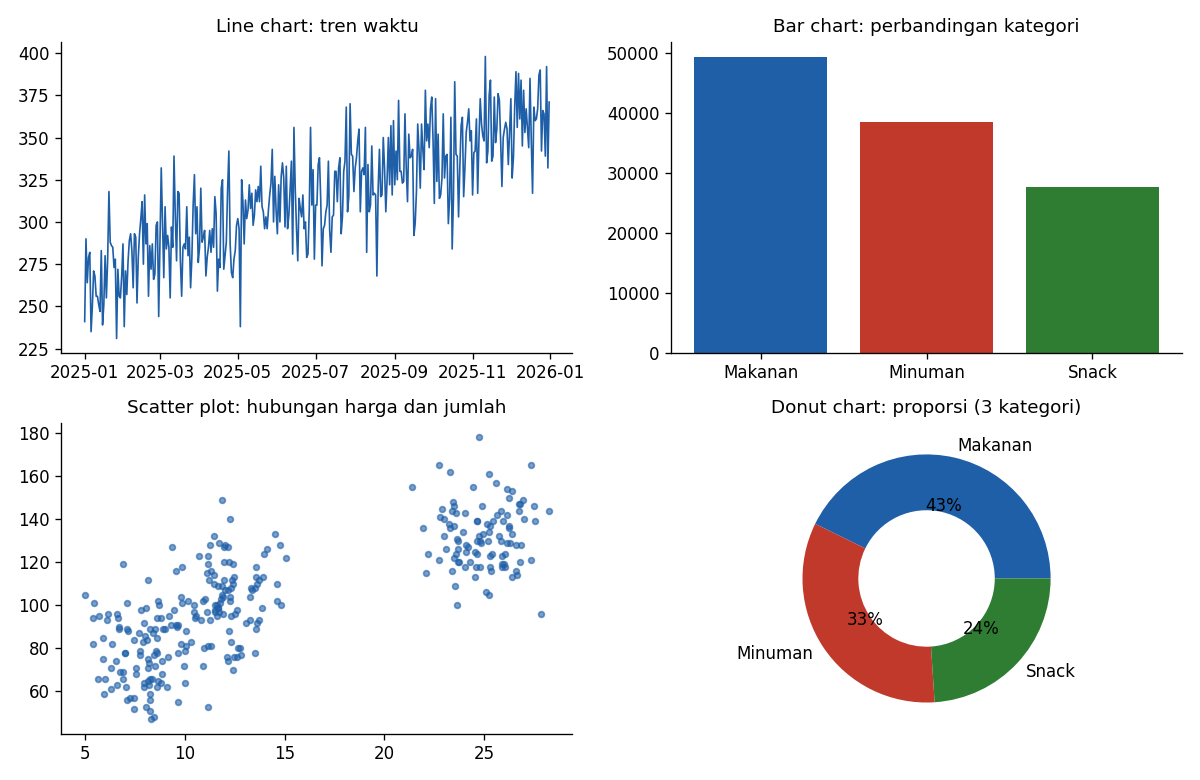


chartjunk_vs_dataink.png


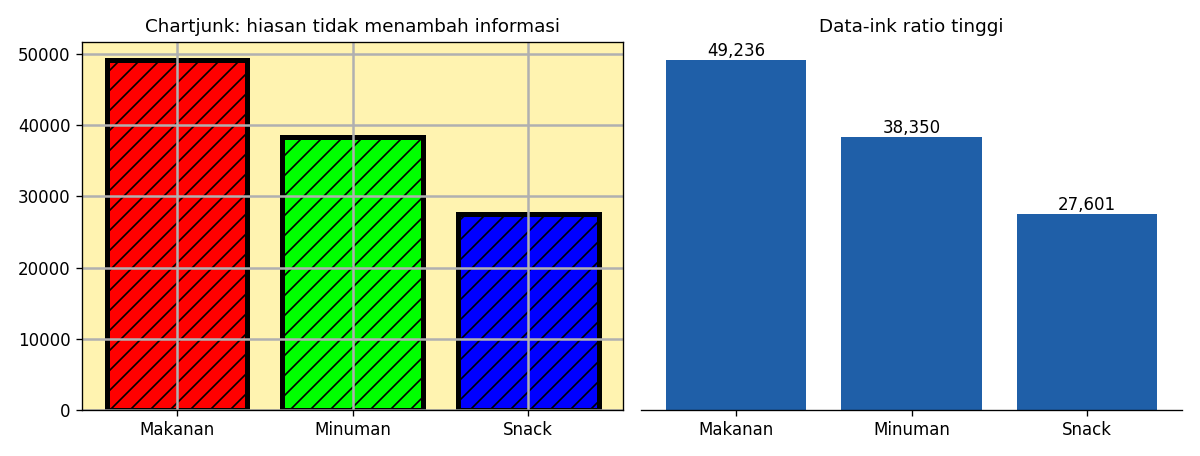


uji_kecepatan.png


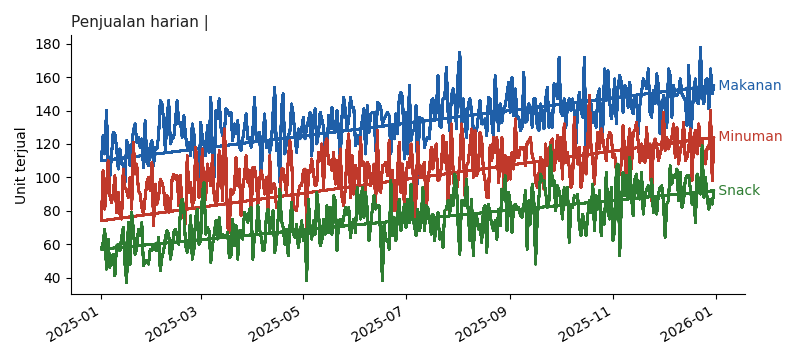

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


laporan_juni.pdf sedang diunduh oleh browser.


In [ ]:
"""
SESI 5 - IMK dan Visualisasi Data: dasbor yang dirancang MENGIKUTI isi modul

 contoh kebutuhan konkret di modul adalah:
  * Fungsional  : "penyaringan data berdasarkan tanggal" dan "ekspor grafik ke PDF"
  * Nonfungsional: "kecepatan pemuatan grafik, kemudahan penggunaan, keterbacaan antarmuka"
Karena itu studi kasusnya (dasbor penjualan toko, persona, dan data) dibuat oleh kode ini
sebagai wadah untuk menerapkan konsep modul.

Konsep modul yang diterapkan:
  M5  User Persona + Use Scenario -> turunan kebutuhan fungsional / nonfungsional (diuji otomatis)
  M2  Beban kognitif (extraneous load dikurangi), konsistensi warna (Similarity pada Gestalt)
  M3  Aksesibilitas WCAG (Perceivable): rasio kontras >= 4,5:1
  M4  Prinsip interaksi: Visibility, Feedback, Constraints, Consistency, Affordance
  M6  Pemilihan jenis grafik, Chartjunk vs Data-Ink (Tufte), Overview -> zoom/filter -> detail (Shneiderman)
"""
import os
import time
from dataclasses import dataclass, field

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

OUT = "output_imk"
os.makedirs(OUT, exist_ok=True)
rng = np.random.default_rng(5)


def judul(t):
    print("\n" + "=" * 72 + f"\n{t}\n" + "=" * 72)


# ============================================================ M5: PERSONA + SKENARIO
@dataclass
class Persona:
    nama: str
    profil: str
    goals: list = field(default_factory=list)
    pain_points: list = field(default_factory=list)
    perilaku: list = field(default_factory=list)


@dataclass
class Skenario:
    konteks: str
    pemicu: str
    tindakan: list
    hasil: str


persona = Persona(
    nama="Rina (fiktif)", profil="Staf admin toko, 28 tahun, terbiasa Excel, memakai laptop dan HP",
    goals=["Melihat tren penjualan dengan cepat", "Melaporkan penjualan bulanan ke pemilik"],
    pain_points=["Grafik lama berantakan dan sulit dibaca", "Menyalin grafik ke laporan memakan waktu"],
    perilaku=["Bekerja di sela melayani pelanggan", "Mengirim laporan dalam bentuk PDF"],
)
skenario = Skenario(
    konteks="Akhir bulan, Rina menyiapkan laporan untuk pemilik toko",
    pemicu="Pemilik meminta ringkasan penjualan Juni",
    tindakan=["Membuka dasbor (overview setahun)", "Memilih rentang tanggal Juni (zoom/filter)",
              "Memilih kategori yang diminati", "Melihat rincian satu hari (detail)", "Mengekspor grafik ke PDF"],
    hasil="Laporan PDF siap dikirim tanpa menyalin manual",
)
judul("M5. PERSONA DAN SKENARIO")
print(f"{persona.nama}: {persona.profil}")
print("Goals       :", "; ".join(persona.goals))
print("Pain points :", "; ".join(persona.pain_points))
print("Skenario    :", skenario.konteks, "->", skenario.pemicu)
for n, t in enumerate(skenario.tindakan, 1):
    print(f"   {n}. {t}")
print("Hasil       :", skenario.hasil)

# ============================================================ DATA SINTETIS
tanggal = pd.date_range("2025-01-01", "2025-12-31", freq="D")
data = pd.DataFrame({"tanggal": np.repeat(tanggal, 3), "kategori": np.tile(["Makanan", "Minuman", "Snack"], len(tanggal))})
data["jumlah"] = (data.kategori.map({"Makanan": 120, "Minuman": 90, "Snack": 60})
                  + np.linspace(0, 30, len(tanggal)).repeat(3) + rng.normal(0, 12, len(data))).round()
data["harga"] = data.kategori.map({"Makanan": 25, "Minuman": 12, "Snack": 8}) + rng.normal(0, 1.5, len(data))

# palet konsisten: satu warna = satu kategori di SEMUA grafik (Similarity/Consistency)
WARNA = {"Makanan": "#1F5FA8", "Minuman": "#C0392B", "Snack": "#2E7D32"}
TEKS, LATAR = "#222222", "#FFFFFF"


# ============================================================ M3: WCAG (Perceivable)
def _lin(c):
    c /= 255
    return c / 12.92 if c <= .03928 else ((c + .055) / 1.055) ** 2.4


def kontras(fg, bg):
    lum = lambda h: sum(w * _lin(int(h[i:i + 2], 16)) for w, i in zip((.2126, .7152, .0722), (1, 3, 5)))
    a, b = sorted((lum(fg), lum(bg)), reverse=True)
    return (a + .05) / (b + .05)


# ============================================================ DASBOR (M4, M6)
class Dasbor:
    def __init__(self, df):
        self.df = df
        self.status = ""

    def overview(self):
        """Shneiderman 1: overview first (total bulanan)."""
        return self.df.groupby(self.df.tanggal.dt.to_period("M")).jumlah.sum()

    def filter(self, mulai, akhir, kategori=None):
        """Shneiderman 2: zoom and filter. Constraints: rentang tidak valid ditolak.
        Feedback: pesan status menjelaskan hasil aksi."""
        mulai, akhir = pd.Timestamp(mulai), pd.Timestamp(akhir)
        if akhir < mulai:
            raise ValueError("Tanggal akhir tidak boleh sebelum tanggal mulai.")        # Constraints
        m = (self.df.tanggal >= mulai) & (self.df.tanggal <= akhir)
        if kategori:
            m &= self.df.kategori == kategori
        hasil = self.df[m]
        self.status = f"{len(hasil):,} baris ditampilkan ({mulai:%d %b} - {akhir:%d %b %Y})"   # Feedback
        return hasil

    def detail(self, tgl):
        """Shneiderman 3: details-on-demand."""
        d = self.df[self.df.tanggal == pd.Timestamp(tgl)][["tanggal", "kategori", "jumlah"]]
        return d

    def gambar(self, sub, nama_file):
        """Grafik garis (tren waktu) yang bersih: data-ink tinggi, label langsung, judul menyatakan filter (Visibility)."""
        fig, ax = plt.subplots(figsize=(8, 3.6))
        for kat, g in sub.groupby("kategori"):
            ax.plot(g.tanggal, g.jumlah, color=WARNA[kat], lw=1.6)
            ax.text(g.tanggal.iloc[-1], g.jumlah.iloc[-1], f" {kat}", color=WARNA[kat], va="center", fontsize=10)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
        ax.set_title(f"Penjualan harian | {self.status}", fontsize=11, loc="left", color=TEKS)
        ax.set_ylabel("Unit terjual", fontsize=10)
        fig.autofmt_xdate()
        fig.tight_layout()
        fig.savefig(nama_file)
        plt.close(fig)


# ============================================================ UJI KEBUTUHAN (M5)
judul("M5. KEBUTUHAN DIUJI OTOMATIS")
d = Dasbor(data)
hasil = []

sub = d.filter("2025-06-01", "2025-06-30")                                   # F1: filter tanggal
ok = sub.tanggal.min() >= pd.Timestamp("2025-06-01") and sub.tanggal.max() <= pd.Timestamp("2025-06-30")
hasil.append(("F1 Filter data berdasarkan tanggal", ok, d.status))

pdf = f"{OUT}/laporan_juni.pdf"                                              # F2: ekspor PDF
d.gambar(sub, pdf)
hasil.append(("F2 Ekspor grafik ke PDF", os.path.exists(pdf) and os.path.getsize(pdf) > 0, pdf))

besar = pd.concat([data] * 20, ignore_index=True)                            # NF1: kecepatan muat (~ 22 ribu x 20 baris)
besar["tanggal"] = pd.to_datetime(besar.tanggal)
t0 = time.perf_counter()
Dasbor(besar).gambar(Dasbor(besar).filter("2025-01-01", "2025-12-31"), f"{OUT}/uji_kecepatan.png")
dt = time.perf_counter() - t0
hasil.append(("NF1 Pemuatan grafik < 2 detik", dt < 2.0, f"{dt:.2f} detik untuk {len(besar):,} baris"))

kontras_min = min(kontras(c, LATAR) for c in list(WARNA.values()) + [TEKS])  # NF3: keterbacaan
hasil.append(("NF3 Keterbacaan: kontras warna >= 4,5:1 (WCAG AA)", kontras_min >= 4.5, f"terendah {kontras_min:.2f}:1"))

try:                                                                          # Constraints (M4)
    d.filter("2025-06-30", "2025-06-01")
    ok_c = False
except ValueError as e:
    ok_c = True
hasil.append(("M4 Constraints: rentang tanggal terbalik ditolak", ok_c, "ValueError ditangkap"))
hasil.append(("M4 Feedback: ada pesan status setelah filter", bool(d.status), d.status))

for nama, ok, ket in hasil:
    print(f"[{'LULUS' if ok else 'GAGAL'}] {nama}  ->  {ket}")
print("\nCatatan: 'kemudahan penggunaan' (NF2) TIDAK bisa diuji otomatis; perlu usability testing")
print("dengan pengguna nyata (mengamati mereka menyelesaikan tugas), bukan hanya kode.")

# ============================================================ M6: OVERVIEW -> FILTER -> DETAIL
judul("M6. SHNEIDERMAN: overview -> zoom/filter -> details-on-demand")
print("Overview (3 bulan pertama):\n", d.overview().head(3).to_string())
sub = d.filter("2025-06-01", "2025-06-30", "Minuman")
print(f"\nZoom/filter: {d.status} | kategori Minuman, total {int(sub.jumlah.sum())}")
print("\nDetail 2025-06-15:\n", d.detail("2025-06-15").to_string(index=False))

# ============================================================ M6: PEMILIHAN GRAFIK + TUFTE
harian = data.groupby("tanggal").jumlah.sum()
total_kat = data.groupby("kategori").jumlah.sum()
fig, ax = plt.subplots(2, 2, figsize=(10, 6.5))
ax[0, 0].plot(harian.index, harian.values, color="#1F5FA8", lw=1)
ax[0, 0].set_title("Line chart: tren waktu", fontsize=11)
ax[0, 1].bar(total_kat.index, total_kat.values, color=[WARNA[k] for k in total_kat.index])
ax[0, 1].set_title("Bar chart: perbandingan kategori", fontsize=11)
contoh = data.sample(300, random_state=0)
ax[1, 0].scatter(contoh.harga, contoh.jumlah, s=12, alpha=.6, color="#1F5FA8")
ax[1, 0].set_title("Scatter plot: hubungan harga dan jumlah", fontsize=11)
ax[1, 1].pie(total_kat.values, labels=total_kat.index, autopct="%1.0f%%", wedgeprops=dict(width=.45),
             colors=[WARNA[k] for k in total_kat.index])
ax[1, 1].set_title("Donut chart: proporsi (3 kategori)", fontsize=11)
for a in ax.ravel()[:3]:
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(f"{OUT}/jenis_grafik.png", dpi=120)
plt.close(fig)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].bar(total_kat.index, total_kat.values, color=["#ff0000", "#00ff00", "#0000ff"], edgecolor="black",
          linewidth=3, hatch="//")
ax[0].grid(True, lw=1.5)
ax[0].set_facecolor("#fff3b0")
ax[0].set_title("Chartjunk: hiasan tidak menambah informasi", fontsize=11)
bars = ax[1].bar(total_kat.index, total_kat.values, color="#1F5FA8")
for b in bars:
    ax[1].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{int(b.get_height()):,}", ha="center", va="bottom")
for s in ("top", "right", "left"):
    ax[1].spines[s].set_visible(False)
ax[1].set_yticks([])
ax[1].set_title("Data-ink ratio tinggi", fontsize=11)
fig.tight_layout()
fig.savefig(f"{OUT}/chartjunk_vs_dataink.png", dpi=120)
plt.close(fig)

print(f"\nFile di '{OUT}/':", sorted(os.listdir(OUT)))

# ============================================================ TAMPILKAN HASIL (Colab / Jupyter)
# Bagian ini ditambahkan agar grafik terlihat langsung di notebook.
# Jika dijalankan sebagai skrip biasa (python file.py), bagian ini dilewati tanpa error.
judul("MENAMPILKAN HASIL")
try:
    notebook = get_ipython() is not None          # noqa: F821  (hanya ada di Colab/Jupyter)
except NameError:
    notebook = False

if notebook:
    from IPython.display import Image, display

    for f in ["jenis_grafik.png", "chartjunk_vs_dataink.png", "uji_kecepatan.png"]:
        print(f"\n{f}")
        display(Image(f"{OUT}/{f}"))

    # PDF tidak bisa ditampilkan di dalam sel, jadi diunduh ke komputer
    try:
        from google.colab import files
        files.download(f"{OUT}/laporan_juni.pdf")
        print("\nlaporan_juni.pdf sedang diunduh oleh browser.")
    except ImportError:
        print("\nBukan Colab: buka laporan_juni.pdf langsung dari folder", OUT)
else:
    print(f"Bukan notebook: semua file ada di folder '{OUT}/'. Buka secara manual.")


1. CITRA OPTIK (SENTINEL-2) vs RADAR (SENTINEL-1)
Piksel optik tertutup awan di scene ini : 22%
Piksel radar tertutup awan              : 0%  (radar menembus awan)

Asumsi peluang awan per akuisisi = 60%, revisit optik 5 hari:
   Peluang >=1 citra optik jernih dalam 10 hari (2 akuisisi): 64%
   Peluang >=1 citra optik jernih dalam 30 hari (6 akuisisi): 95%

Keterbatasan radar: kemampuan mendeteksi objek DI BAWAH kanopi terbatas. Pada simulasi ini
penebangan selektif sengaja diberi perubahan radar yang lemah (lihat SPEKTRAL, kelas 2).

2. DEFORESTATION ALERTS (deteksi perubahan per ubin 16x16 piksel = 2,56 ha)
Ubin berisi gangguan sebenarnya        : 14 dari 36
  terdeteksi ALERT optik               : 9
  terdeteksi ALERT radar (awan)        : 0
  tertutup awan, tidak terdeteksi      : 3
  lolos (ubah < 5% piksel)             : 2  -> ['Penebangan', 'Penebangan']
Alarm palsu (ubin hutan utuh jadi ALERT): 0

3. KLASIFIKASI PENYEBAB: dataset berlabel dan pelatihan model
Model            :

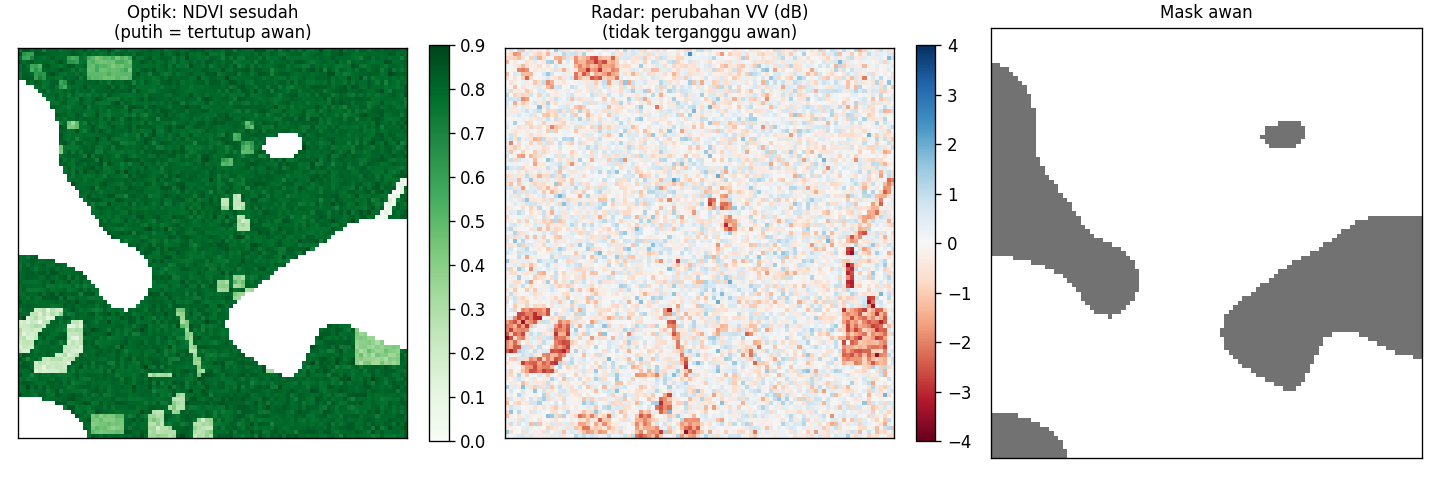


2_contoh_ubin.png


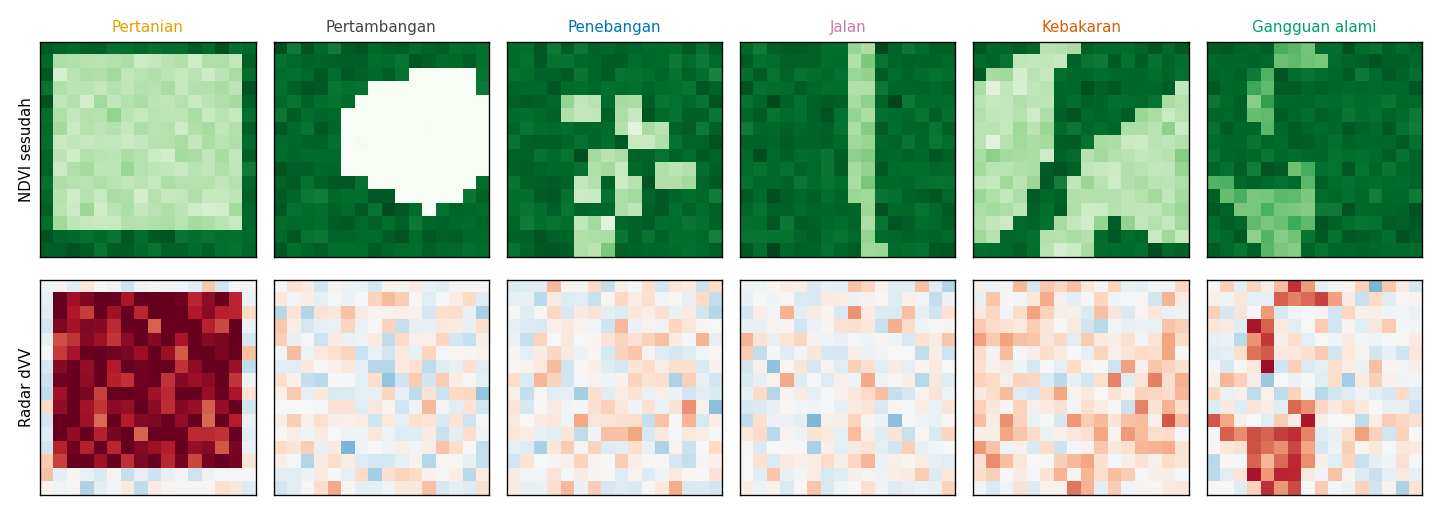


3_confusion_matrix.png


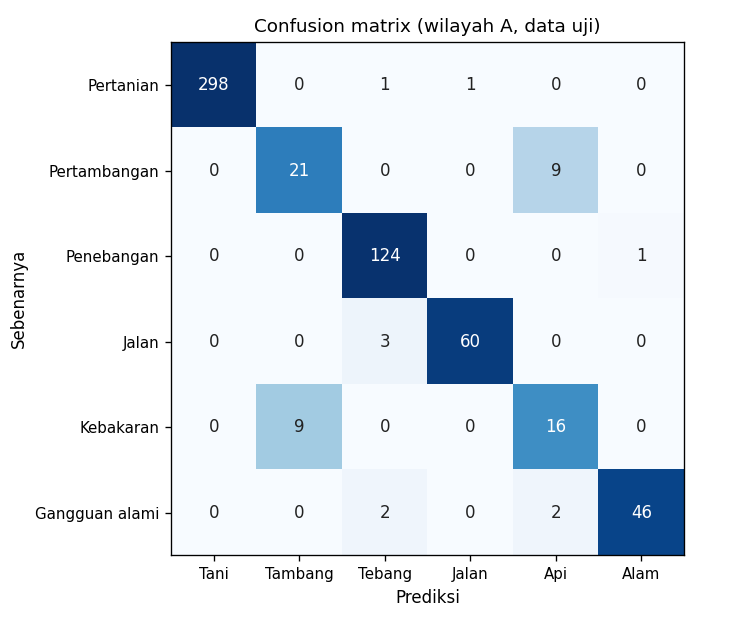


4_f1_per_kelas.png


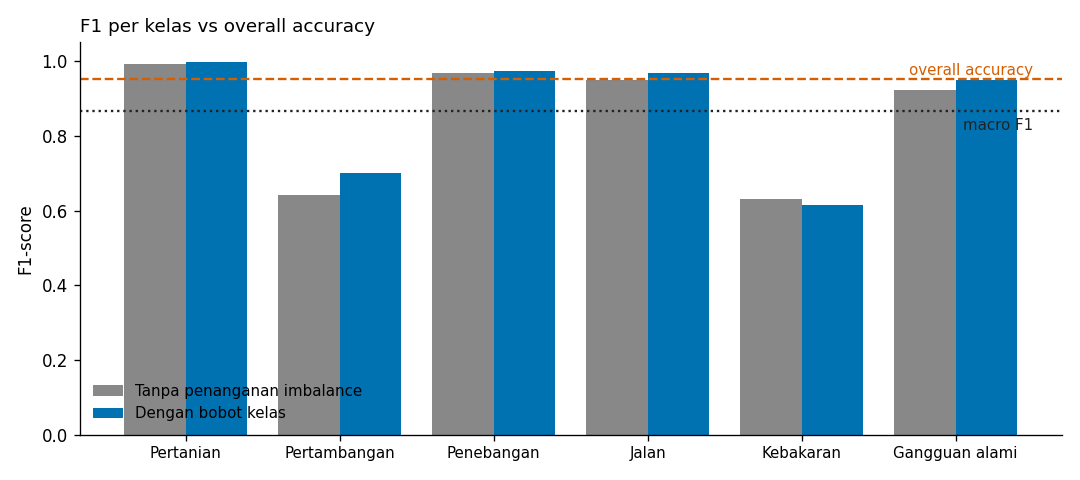


5_peta_alert.png


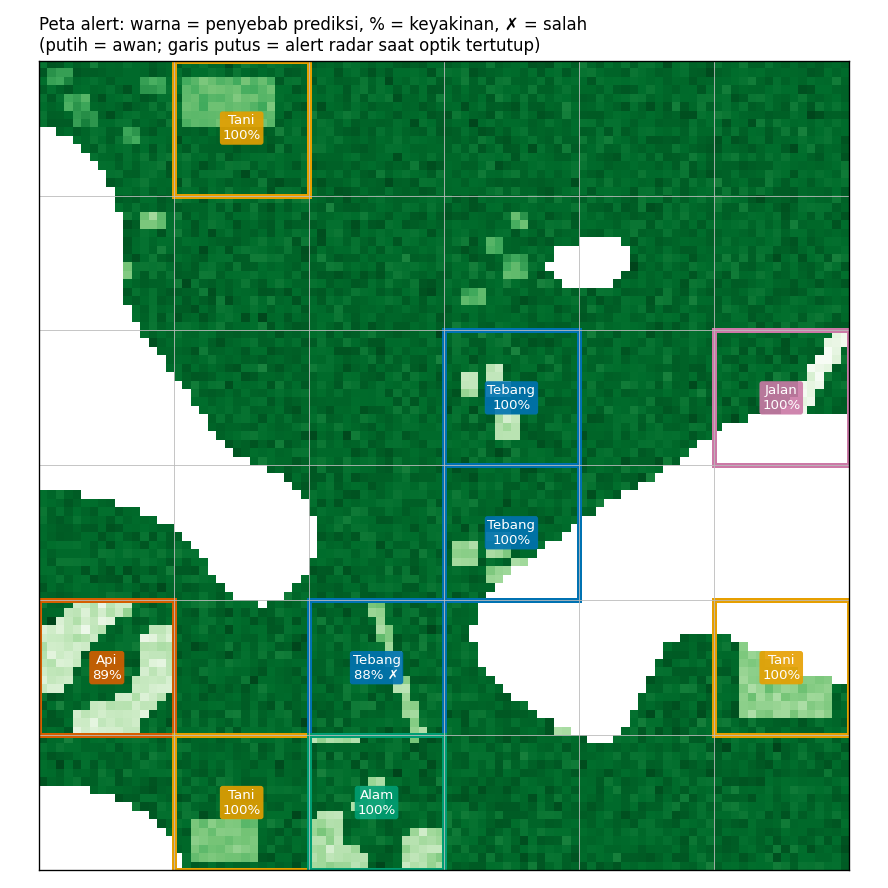

In [1]:
"""
SESI 6 - Pemantauan Deforestasi Menggunakan Citra Satelit dan Artificial Intelligence

Konsep resume -> bagian kode:
  1. Citra optik (Sentinel-2) terganggu awan, radar (Sentinel-1) tidak       -> Bagian 1
  2. Deforestation alerts dari perubahan tutupan                             -> Bagian 2
  3. Klasifikasi penyebab (pertanian, tambang, tebang, jalan, api, alam)
     memakai CNN yang dilatih dari citra berlabel                            -> Bagian 3
  4. Evaluasi: overall accuracy vs macro F1 (kelas dominan = pertanian),
     performa berbeda antarwilayah                                           -> Bagian 4 dan 5
  5. Validasi lapangan untuk hasil yang tidak yakin                          -> Bagian 6
  6. Frekuensi pembaruan: mingguan/bulanan vs sensor termal untuk kebakaran  -> Bagian 7
"""
import os
import warnings

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from scipy.ndimage import gaussian_filter, label
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

try:
    import torch
    import torch.nn as nn
    ADA_TORCH = True
except ImportError:
    ADA_TORCH = False

warnings.filterwarnings("ignore")
SEED = 6
OUT = "output_deforestasi"
os.makedirs(OUT, exist_ok=True)
rng = np.random.default_rng(SEED)


def judul(t):
    print("\n" + "=" * 72 + f"\n{t}\n" + "=" * 72)


# ====================================================================== KONSTANTA
UK = 16                      # ukuran ubin 16x16 piksel; 1 piksel Sentinel-2 = 10 m -> 0,01 ha
HA_PIKSEL = 0.01
KELAS = ["Pertanian", "Pertambangan", "Penebangan", "Jalan", "Kebakaran", "Gangguan alami"]
SINGKAT = ["Tani", "Tambang", "Tebang", "Jalan", "Api", "Alam"]
# palet Okabe-Ito (aman untuk buta warna); satu warna = satu kelas di SEMUA gambar
WARNA = ["#E69F00", "#444444", "#0072B2", "#CC79A7", "#D55E00", "#009E73"]
SALURAN = ["NDVI sebelum", "NDVI sesudah", "Merah (B4)", "SWIR (B11)", "Radar dVV (dB)", "Radar dVH (dB)"]

# Ciri spektral tiap penyebab: (rata-rata, simpangan antar-sampel). Angkanya ASUMSI ilustratif.
SPEKTRAL = {
    0: dict(ndvi=(0.35, 0.12), red=(0.12, 0.04), swir=(0.20, 0.05), vv=(-1.5, 1.4), vh=(-1.5, 1.4), noise=0.04),
    1: dict(ndvi=(0.16, 0.09), red=(0.22, 0.06), swir=(0.30, 0.06), vv=(0.5, 1.5), vh=(0.2, 1.5), noise=0.05),
    2: dict(ndvi=(0.45, 0.12), red=(0.10, 0.04), swir=(0.18, 0.05), vv=(-0.8, 1.0), vh=(-0.7, 1.0), noise=0.05),
    3: dict(ndvi=(0.28, 0.12), red=(0.17, 0.05), swir=(0.25, 0.06), vv=(-1.0, 1.3), vh=(-1.0, 1.3), noise=0.05),
    4: dict(ndvi=(0.20, 0.09), red=(0.16, 0.05), swir=(0.31, 0.06), vv=(-0.5, 1.0), vh=(-0.5, 1.0), noise=0.05),
    5: dict(ndvi=(0.38, 0.13), red=(0.11, 0.04), swir=(0.17, 0.05), vv=(-2.2, 1.5), vh=(-2.5, 1.5), noise=0.05),
}
# Wilayah B = kondisi berbeda (musim/sensor/vegetasi) -> menguji generalisasi antarwilayah
WILAYAH = {"A": dict(ndvi=0.0, red=0.0, swir=0.0, radar=0.0, noise=1.0),
           "B": dict(ndvi=-0.07, red=0.03, swir=0.04, radar=-0.8, noise=1.4)}


# ====================================================================== GENERATOR DATA
def _blob(r, sigma, frac):
    z = gaussian_filter(r.normal(size=(UK, UK)), sigma, mode="wrap")
    return z > np.quantile(z, 1 - frac)


def _bentuk(kls, r):
    """Bentuk spasial khas tiap penyebab (inilah yang dipelajari 'mata' CNN)."""
    yy, xx = np.mgrid[0:UK, 0:UK]
    if kls == 0:                                   # pertanian: blok persegi panjang
        h, w = r.integers(5, 15, 2)
        y0, x0 = r.integers(0, UK - h + 1), r.integers(0, UK - w + 1)
        return (yy >= y0) & (yy < y0 + h) & (xx >= x0) & (xx < x0 + w)
    if kls == 1:
        return _blob(r, 3, r.uniform(.30, .50))    # tambang: area terbuka tak beraturan
    if kls == 2:                                   # penebangan selektif: bintik kecil tersebar
        m = np.zeros((UK, UK), bool)
        for _ in range(r.integers(5, 10)):
            y, x = r.integers(1, UK - 2, 2)
            m[y:y + r.integers(2, 4), x:x + r.integers(2, 4)] = True
        return m
    if kls == 3:                                   # jalan: garis tipis
        ang = r.uniform(0, np.pi)
        cy, cx = r.uniform(5, 11, 2)
        return np.abs((xx - cx) * np.sin(ang) - (yy - cy) * np.cos(ang)) < r.uniform(.8, 1.5)
    if kls == 4:
        return _blob(r, 3, r.uniform(.35, .60))    # kebakaran: bekas bakar tak beraturan
    return _blob(r, 1.5, r.uniform(.15, .35))      # gangguan alami: bercak-bercak


def buat_patch(kls, r, wil="A"):
    """Ubin 6 saluran x 16 x 16. kls=None -> hutan utuh (tanpa perubahan)."""
    w = WILAYAH[wil]
    nz = w["noise"]
    ndvi_b = 0.80 + r.normal(0, .03, (UK, UK)) * nz
    ndvi_a = 0.80 + w["ndvi"] + r.normal(0, .03, (UK, UK)) * nz
    red = 0.04 + w["red"] + r.normal(0, .01, (UK, UK)) * nz
    swir = 0.12 + w["swir"] + r.normal(0, .01, (UK, UK)) * nz
    vv = r.normal(0, .6, (UK, UK)) * nz
    vh = r.normal(0, .6, (UK, UK)) * nz
    if kls is not None:
        p, m = SPEKTRAL[kls], _bentuk(kls, r)
        n, tek = int(m.sum()), SPEKTRAL[kls]["noise"] * nz
        ndvi_a[m] = r.normal(*p["ndvi"]) + w["ndvi"] + r.normal(0, tek, n)
        red[m] = r.normal(*p["red"]) + w["red"] + r.normal(0, tek / 2, n)
        swir[m] = r.normal(*p["swir"]) + w["swir"] + r.normal(0, tek / 2, n)
        vv[m] = r.normal(*p["vv"]) + w["radar"] + r.normal(0, .6 * nz, n)
        vh[m] = r.normal(*p["vh"]) + w["radar"] + r.normal(0, .6 * nz, n)
    return np.stack([ndvi_b, ndvi_a, red, swir, vv, vh]).astype(np.float32)


def buat_dataset(jumlah, wil, r):
    X, y = [], []
    for k, n in enumerate(jumlah):
        for _ in range(n):
            X.append(buat_patch(k, r, wil))
            y.append(k)
    return np.stack(X), np.array(y)


def buat_scene(r, n_ubin=6, n_event=14, p_kelas=(.30, .10, .20, .15, .10, .15)):
    """Satu 'scene' 96x96 piksel berisi ubin hutan dan ubin gangguan + tutupan awan pada citra optik."""
    N = n_ubin * UK
    scene = np.zeros((6, N, N), np.float32)
    benar = -np.ones((n_ubin, n_ubin), int)
    event = set(r.choice(n_ubin * n_ubin, n_event, replace=False).tolist())
    for i in range(n_ubin):
        for j in range(n_ubin):
            if i * n_ubin + j in event:
                benar[i, j] = r.choice(6, p=p_kelas)
            scene[:, i * UK:(i + 1) * UK, j * UK:(j + 1) * UK] = buat_patch(
                benar[i, j] if benar[i, j] >= 0 else None, r)
    z = gaussian_filter(r.normal(size=(N, N)), 9)
    awan = z > np.quantile(z, .78)                          # ~22% tertutup awan
    return scene, benar, awan


# ====================================================================== MODEL
def fitur_manual(X):
    """Pengganti CNN (jika PyTorch tidak ada): statistik tiap saluran + ciri bentuk area berubah."""
    out = []
    for p in X:
        ubah = (p[0] - p[1]) > 0.25
        f = []
        for c in range(6):
            f += [p[c].mean(), p[c].std(), p[c].min(), p[c].max()]
        n = int(ubah.sum())
        f.append(n / ubah.size)
        if n > 2:
            yy, xx = np.nonzero(ubah)
            ev = np.linalg.eigvalsh(np.cov(np.vstack([yy, xx])))
            f.append(ev[1] / (ev[0] + 1e-3))              # kelonjongan (jalan = sangat lonjong)
        else:
            f.append(1.0)
        lab, nl = label(ubah)
        f += [nl, (np.bincount(lab.ravel())[1:].max() / n) if n > 0 else 0]
        out.append(f)
    return np.array(out)


class ModelFitur:
    nama = "Random Forest (pengganti CNN)"

    def __init__(self, seimbang):
        self.rf = RandomForestClassifier(n_estimators=300, random_state=SEED,
                                         class_weight="balanced_subsample" if seimbang else None)

    def fit(self, X, y):
        self.rf.fit(fitur_manual(X), y)
        return self

    def predict_proba(self, X):
        return self.rf.predict_proba(fitur_manual(X))


class ModelCNN:
    nama = "CNN (PyTorch)"

    def __init__(self, seimbang, epoch=25):
        self.seimbang, self.epoch = seimbang, epoch

    def fit(self, X, y):
        torch.manual_seed(SEED)
        self.mu = X.mean(axis=(0, 2, 3), keepdims=True)
        self.sd = X.std(axis=(0, 2, 3), keepdims=True) + 1e-6
        Xt = torch.tensor((X - self.mu) / self.sd, dtype=torch.float32)
        yt = torch.tensor(y, dtype=torch.long)
        self.net = nn.Sequential(
            nn.Conv2d(X.shape[1], 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
            nn.Flatten(), nn.Linear(64, len(KELAS)))
        bobot = None
        if self.seimbang:                                    # kelas langka diberi bobot lebih besar
            cnt = np.bincount(y, minlength=len(KELAS))
            bobot = torch.tensor(len(y) / (len(KELAS) * np.maximum(cnt, 1)), dtype=torch.float32)
        loss_fn = nn.CrossEntropyLoss(weight=bobot)
        opt = torch.optim.Adam(self.net.parameters(), lr=2e-3)
        for _ in range(self.epoch):
            self.net.train()
            urut = torch.randperm(len(Xt))
            for i in range(0, len(Xt), 64):
                idx = urut[i:i + 64]
                opt.zero_grad()
                loss_fn(self.net(Xt[idx]), yt[idx]).backward()
                opt.step()
        return self

    def predict_proba(self, X):
        self.net.eval()
        with torch.no_grad():
            logit = self.net(torch.tensor((X - self.mu) / self.sd, dtype=torch.float32))
            return torch.softmax(logit, dim=1).numpy()


def buat_model(seimbang):
    return ModelCNN(seimbang) if ADA_TORCH else ModelFitur(seimbang)


def ringkas(y, pred):
    return accuracy_score(y, pred), f1_score(y, pred, average="macro", zero_division=0)


# ====================================================================== SCENE (dipakai Bagian 1, 2, 6)
scene_r = np.random.default_rng(SEED + 1)
scene, benar_ubin, awan = buat_scene(scene_r)
N = scene.shape[1]
scene_opt = scene.copy()
scene_opt[1:4, awan] = np.nan             # awan menutup citra OPTIK sesudah (NDVI sesudah, merah, SWIR)

# ====================================================================== 1. OPTIK vs RADAR
judul("1. CITRA OPTIK (SENTINEL-2) vs RADAR (SENTINEL-1)")
print(f"Piksel optik tertutup awan di scene ini : {awan.mean():.0%}")
print("Piksel radar tertutup awan              : 0%  (radar menembus awan)")
p_awan = 0.6      # ASUMSI: peluang sebuah akuisisi tertutup awan di wilayah tropis
print(f"\nAsumsi peluang awan per akuisisi = {p_awan:.0%}, revisit optik 5 hari:")
for hari in (10, 30):
    n = hari // 5
    print(f"   Peluang >=1 citra optik jernih dalam {hari:2d} hari ({n} akuisisi): {1 - p_awan ** n:.0%}")
print("\nKeterbatasan radar: kemampuan mendeteksi objek DI BAWAH kanopi terbatas. Pada simulasi ini")
print("penebangan selektif sengaja diberi perubahan radar yang lemah (lihat SPEKTRAL, kelas 2).")

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
tampil = np.ma.masked_invalid(scene_opt[1])
cm = plt.get_cmap("Greens").copy()
cm.set_bad("#FFFFFF")
im0 = ax[0].imshow(tampil, cmap=cm, vmin=0, vmax=0.9)
ax[0].set_title("Optik: NDVI sesudah\n(putih = tertutup awan)", fontsize=10)
im1 = ax[1].imshow(scene[4], cmap="RdBu", vmin=-4, vmax=4)
ax[1].set_title("Radar: perubahan VV (dB)\n(tidak terganggu awan)", fontsize=10)
ax[2].imshow(awan, cmap="Greys", vmin=0, vmax=1.6)
ax[2].set_title("Mask awan", fontsize=10)
for a in ax:
    a.set_xticks([]); a.set_yticks([])
fig.colorbar(im0, ax=ax[0], fraction=.046); fig.colorbar(im1, ax=ax[1], fraction=.046)
fig.tight_layout(); fig.savefig(f"{OUT}/1_optik_vs_radar.png", dpi=120); plt.close(fig)

# ====================================================================== 2. DEFORESTATION ALERTS
judul("2. DEFORESTATION ALERTS (deteksi perubahan per ubin 16x16 piksel = 2,56 ha)")
AMBANG_DROP, MIN_FRAC = 0.25, 0.05
baris, nb = [], benar_ubin.shape[0]
for i in range(nb):
    for j in range(nb):
        sl = (slice(None), slice(i * UK, (i + 1) * UK), slice(j * UK, (j + 1) * UK))
        t = scene_opt[sl]
        frac_awan = np.isnan(t[1]).mean()
        if frac_awan > 0.5:
            # radar tidak terganggu awan: alert jika >=10% piksel turun lebih dari 1,5 dB
            status = "ALERT RADAR (tertutup awan)" if (t[4] < -1.5).mean() >= 0.10 else "Tertutup awan, tak ada alert"
            frac = np.nan
        else:
            drop = t[0] - t[1]
            frac = float(np.nansum(drop > AMBANG_DROP) / drop.size)
            status = "ALERT" if frac >= MIN_FRAC else "Normal"
        baris.append(dict(i=i, j=j, awan=frac_awan, frac_ubah=frac, luas_ha=(frac * UK * UK * HA_PIKSEL)
                          if frac == frac else np.nan, status=status, benar=benar_ubin[i, j]))
alert = pd.DataFrame(baris)
n_event = int((benar_ubin >= 0).sum())
ada = alert[alert.benar >= 0]
print(f"Ubin berisi gangguan sebenarnya        : {n_event} dari {nb * nb}")
print(f"  terdeteksi ALERT optik               : {int((ada.status == 'ALERT').sum())}")
print(f"  terdeteksi ALERT radar (awan)        : {int(ada.status.str.startswith('ALERT RADAR').sum())}")
print(f"  tertutup awan, tidak terdeteksi      : {int(ada.status.str.startswith('Tertutup').sum())}")
lolos = ada[(ada.status == "Normal")]
print(f"  lolos (ubah < {MIN_FRAC:.0%} piksel)             : {len(lolos)}"
      + (f"  -> {[KELAS[int(k)] for k in lolos.benar]}" if len(lolos) else ""))
print(f"Alarm palsu (ubin hutan utuh jadi ALERT): "
      f"{int(((alert.benar < 0) & alert.status.str.startswith('ALERT')).sum())}")

# ====================================================================== 3. DATASET + CNN
judul("3. KLASIFIKASI PENYEBAB: dataset berlabel dan pelatihan model")
JUMLAH_A = [1200, 120, 500, 250, 100, 200]            # PERTANIAN SANGAT DOMINAN (sesuai resume)
JUMLAH_B = [400, 60, 150, 100, 60, 80]
rA, rB = np.random.default_rng(SEED + 2), np.random.default_rng(SEED + 3)
XA, yA = buat_dataset(JUMLAH_A, "A", rA)
XB, yB = buat_dataset(JUMLAH_B, "B", rB)
Xtr, Xte, ytr, yte = train_test_split(XA, yA, test_size=0.25, random_state=SEED, stratify=yA)
print(f"Model            : {(ModelCNN if ADA_TORCH else ModelFitur).nama}")
print(f"Wilayah A (latih): {len(ytr)} ubin | uji: {len(yte)} ubin | Wilayah B (uji lintas wilayah): {len(yB)} ubin")
print("Distribusi kelas wilayah A:", dict(zip(KELAS, np.bincount(yA).tolist())))

model_biasa = buat_model(seimbang=False).fit(Xtr, ytr)
model_bobot = buat_model(seimbang=True).fit(Xtr, ytr)

# contoh ubin tiap kelas
fig, ax = plt.subplots(2, 6, figsize=(12, 4.4))
for k in range(6):
    p = buat_patch(k, np.random.default_rng(k + 50))
    ax[0, k].imshow(p[1], cmap="Greens", vmin=0, vmax=.9)
    ax[0, k].set_title(KELAS[k], fontsize=9, color=WARNA[k])
    ax[1, k].imshow(p[4], cmap="RdBu", vmin=-4, vmax=4)
    ax[0, k].set_xticks([]); ax[0, k].set_yticks([]); ax[1, k].set_xticks([]); ax[1, k].set_yticks([])
ax[0, 0].set_ylabel("NDVI sesudah", fontsize=9); ax[1, 0].set_ylabel("Radar dVV", fontsize=9)
fig.tight_layout(); fig.savefig(f"{OUT}/2_contoh_ubin.png", dpi=120); plt.close(fig)

# ====================================================================== 4. EVALUASI
judul("4. EVALUASI: overall accuracy BELUM cukup, lihat macro F1 dan tiap kelas")
hasil = {}
for nama, mdl in [("Tanpa penanganan imbalance", model_biasa), ("Dengan bobot kelas", model_bobot)]:
    pred = mdl.predict_proba(Xte).argmax(1)
    acc, f1m = ringkas(yte, pred)
    hasil[nama] = (pred, acc, f1m, f1_score(yte, pred, average=None, zero_division=0))
    print(f"{nama:<28} overall accuracy={acc:.3f} | macro F1={f1m:.3f}")
print("\nRincian per kelas (model dengan bobot kelas):")
print(classification_report(yte, hasil["Dengan bobot kelas"][0], target_names=KELAS, digits=3, zero_division=0))
print("Catatan: jika overall accuracy tinggi tetapi F1 kelas langka (tambang, kebakaran) rendah,")
print("model tampak bagus padahal sebenarnya lemah pada kelas yang justru penting.")

cmx = confusion_matrix(yte, hasil["Dengan bobot kelas"][0], labels=range(6))
cmn = cmx / cmx.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.2, 5.2))
ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for a in range(6):
    for b in range(6):
        ax.text(b, a, cmx[a, b], ha="center", va="center", color="white" if cmn[a, b] > .5 else "#222222")
ax.set_xticks(range(6)); ax.set_xticklabels(SINGKAT, fontsize=9)
ax.set_yticks(range(6)); ax.set_yticklabels(KELAS, fontsize=9)
ax.set_xlabel("Prediksi"); ax.set_ylabel("Sebenarnya"); ax.set_title("Confusion matrix (wilayah A, data uji)", fontsize=11)
fig.tight_layout(); fig.savefig(f"{OUT}/3_confusion_matrix.png", dpi=120); plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(6)
ax.bar(x - .2, hasil["Tanpa penanganan imbalance"][3], .4, color="#888888", label="Tanpa penanganan imbalance")
ax.bar(x + .2, hasil["Dengan bobot kelas"][3], .4, color="#0072B2", label="Dengan bobot kelas")
ax.axhline(hasil["Dengan bobot kelas"][1], color="#D55E00", ls="--", lw=1.4)
ax.text(5.5, hasil["Dengan bobot kelas"][1] + .01, "overall accuracy", color="#D55E00", ha="right", fontsize=9)
ax.axhline(hasil["Dengan bobot kelas"][2], color="#222222", ls=":", lw=1.4)
ax.text(5.5, hasil["Dengan bobot kelas"][2] - .05, "macro F1", color="#222222", ha="right", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(KELAS, fontsize=9); ax.set_ylim(0, 1.05); ax.set_ylabel("F1-score")
ax.set_title("F1 per kelas vs overall accuracy", fontsize=11, loc="left")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="lower left")
fig.tight_layout(); fig.savefig(f"{OUT}/4_f1_per_kelas.png", dpi=120); plt.close(fig)

# ====================================================================== 5. ANTARWILAYAH
judul("5. PERFORMA BERBEDA ANTARWILAYAH (model dilatih di A, diuji di A dan B)")
pA = model_bobot.predict_proba(Xte).argmax(1)
pB = model_bobot.predict_proba(XB).argmax(1)
aA, fA = ringkas(yte, pA)
aB, fB = ringkas(yB, pB)
print(f"{'Wilayah':<26}{'Accuracy':>10}{'Macro F1':>10}")
print(f"{'A (wilayah latih)':<26}{aA:>10.3f}{fA:>10.3f}")
print(f"{'B (wilayah baru)':<26}{aB:>10.3f}{fB:>10.3f}")
print(f"Penurunan macro F1 dari A ke B: {fA - fB:.3f}")
print("Penyebab di simulasi ini: nilai spektral wilayah B bergeser (musim/sensor/vegetasi berbeda).")
print("Implikasi: model perlu dievaluasi, bahkan dilatih ulang/disesuaikan, untuk tiap wilayah baru.")

# ====================================================================== 6. END-TO-END + VALIDASI LAPANGAN
judul("6. ALERT -> KLASIFIKASI PENYEBAB -> VALIDASI LAPANGAN")
AMBANG_YAKIN = 0.70


def ubin_aman(i, j):
    """Ambil ubin dari scene optik; piksel awan (NaN) diisi nilai hutan agar bisa masuk model."""
    t = scene_opt[:, i * UK:(i + 1) * UK, j * UK:(j + 1) * UK].copy()
    nanm = np.isnan(t[1])
    t[1][nanm], t[2][nanm], t[3][nanm] = t[0][nanm], 0.04, 0.12
    return t


al = alert[alert.status == "ALERT"].copy().reset_index(drop=True)
if len(al):
    proba = model_bobot.predict_proba(np.stack([ubin_aman(r.i, r.j) for r in al.itertuples()]))
    al["prediksi"] = [KELAS[k] for k in proba.argmax(1)]
    al["yakin"] = proba.max(1)
    al["sebenarnya"] = [KELAS[int(k)] if k >= 0 else "(hutan utuh)" for k in al.benar]
    al["benar?"] = np.where(al.prediksi == al.sebenarnya, "ya", "TIDAK")
    al["tindak lanjut"] = np.where(al.yakin < AMBANG_YAKIN, "VERIFIKASI LAPANGAN", "sampel validasi")
    tabel = al[["i", "j", "luas_ha", "prediksi", "yakin", "sebenarnya", "benar?", "tindak lanjut"]].copy()
    tabel["luas_ha"] = tabel.luas_ha.round(2)
    tabel["yakin"] = tabel.yakin.round(2)
    print(tabel.to_string(index=False))
    print(f"\nAkurasi pada {len(al)} ubin alert: {(al['benar?'] == 'ya').mean():.0%} "
          "(sampel kecil, hanya ilustrasi)")
else:
    print("Tidak ada alert optik pada scene ini.")

print("\nTrade-off ambang keyakinan (data uji wilayah A):")
pr = model_bobot.predict_proba(Xte)
print(f"{'Ambang':>8}{'Ubin diterima otomatis':>26}{'Akurasi di sana':>18}")
for th in (0.5, 0.7, 0.9):
    m = pr.max(1) >= th
    print(f"{th:>8.1f}{m.mean():>26.0%}{(pr.argmax(1)[m] == yte[m]).mean():>18.1%}")
print("Makin tinggi ambang -> makin akurat, tetapi makin banyak ubin harus dicek lapangan.")
print("Ingat: citra tidak menjelaskan penyebab mendasar secara lengkap; validasi lapangan tetap perlu.")

# peta alert
fig, ax = plt.subplots(figsize=(7.4, 7.4))
cm2 = plt.get_cmap("Greens").copy()
cm2.set_bad("#FFFFFF")
ax.imshow(np.ma.masked_invalid(scene_opt[1]), cmap=cm2, vmin=0, vmax=.9)
for k in range(1, nb):
    ax.axhline(k * UK - .5, color="#BBBBBB", lw=.5); ax.axvline(k * UK - .5, color="#BBBBBB", lw=.5)
for r in alert.itertuples():
    if r.status.startswith("ALERT RADAR"):
        ax.add_patch(Rectangle((r.j * UK - .5, r.i * UK - .5), UK, UK, fill=False, ec="#222222", lw=2, ls="--"))
        ax.text(r.j * UK + UK / 2 - .5, r.i * UK + UK / 2 - .5, "radar", ha="center", va="center", fontsize=8,
                bbox=dict(fc="white", ec="none", alpha=.8))
for r in al.itertuples():
    k = KELAS.index(r.prediksi)
    ax.add_patch(Rectangle((r.j * UK - .5, r.i * UK - .5), UK, UK, fill=False, ec=WARNA[k], lw=3))
    salah = "" if r.prediksi == r.sebenarnya else " ✗"
    ax.text(r.j * UK + UK / 2 - .5, r.i * UK + UK / 2 - .5, f"{SINGKAT[k]}\n{r.yakin:.0%}{salah}",
            ha="center", va="center", fontsize=8, color="white",
            bbox=dict(fc=WARNA[k], ec="none", alpha=.9, boxstyle="round,pad=.2"))
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Peta alert: warna = penyebab prediksi, % = keyakinan, ✗ = salah\n"
             "(putih = awan; garis putus = alert radar saat optik tertutup)", fontsize=10, loc="left")
fig.tight_layout(); fig.savefig(f"{OUT}/5_peta_alert.png", dpi=120); plt.close(fig)

# ====================================================================== 7. FREKUENSI PEMBARUAN (KEBAKARAN)
judul("7. FREKUENSI PEMBARUAN: mingguan / bulanan vs sensor termal (kebakaran)")
# ASUMSI ILUSTRATIF: kebakaran mulai kecil lalu meluas ~25% per hari (tidak berasal dari resume)
A0, TUMBUH, TUNDA_PROSES, LUAS_MAKS = 2.0, 1.25, 1.0, 1000.0
r7 = np.random.default_rng(SEED + 7)
opsi = [("Klasifikasi bulanan", 30), ("Alert mingguan", 7), ("Sensor termal (harian)", 1)]
print(f"Asumsi: api awal {A0:.0f} ha, meluas {TUMBUH - 1:.0%}/hari (maks {LUAS_MAKS:,.0f} ha), pemrosesan {TUNDA_PROSES:.0f} hari.")
print(f"{'Sumber data':<26}{'Rata2 jeda':>12}{'Jeda terburuk':>15}{'Luas rata2 saat terdeteksi':>28}")
for nama, T in opsi:
    mulai = r7.uniform(0, 365, 20000)
    jeda = (T - (mulai % T)) % T + TUNDA_PROSES
    luas = np.minimum(A0 * TUMBUH ** jeda, LUAS_MAKS)
    print(f"{nama:<26}{jeda.mean():>9.1f} hr{T + TUNDA_PROSES:>12.0f} hr{luas.mean():>22,.0f} ha")
print("\nPemilihan sumber data harus sesuai jenis gangguan: deforestasi bertahap cukup dengan alert")
print("mingguan/bulanan, tetapi kebakaran yang cepat meluas membutuhkan data lebih sering (termal).")

print(f"\nFile di '{OUT}/':", sorted(os.listdir(OUT)))

# ====================================================================== TAMPILKAN HASIL (Colab / Jupyter)
judul("MENAMPILKAN HASIL")
try:
    notebook = get_ipython() is not None          # noqa: F821  (hanya ada di Colab/Jupyter)
except NameError:
    notebook = False

if notebook:
    from IPython.display import Image, display
    for f in sorted(os.listdir(OUT)):
        if f.endswith(".png"):
            print(f"\n{f}")
            display(Image(f"{OUT}/{f}"))
else:
    print(f"Bukan notebook: semua gambar ada di folder '{OUT}/'.")